# Vanilla DQN for Pendulum under Four Gravity Settings

**Team:** Hoon Chun Fei and You Xuan (joint work)<br>
**Environment:** OpenAI Gym 0.17.3 `Pendulum-v0`<br>
**Gravities:** `g = 10`, `g = 0`, `g = -10`, `g = 15`

> The implementation and combined 12-agent evaluation were developed jointly. This is Chun Fei's copy of the notebook, containing his detailed analysis of `g=10`, his `g=-10` and `g=15` runs, checkpoint integration and final evaluation/video generation.

This notebook implements an understandable **Vanilla DQN** with experience replay, separate Main and Target networks, state normalisation and an odd discrete torque grid containing zero. It follows the team's final controlled experimental design:

- Epsilon is the probability of a random action. It starts at `1.0`, stays unchanged during replay warm-up, then decays to the very low value `0.01`.
- Supergravity `g=15` includes 15 actions to provide finer torque resolution after the shorter action-screening runs remained variable.
- A controlled hard-versus-soft comparison was performed at `g=10`. The final agents use the better-supported **hard Target-DQN update once per episode**; soft updating with `tau=0.01` is retained only as comparison evidence.
- No fixed random seeds are set. `run1`, `run2` and `run3` are independent initialisations, not seed values.
- Each final agent trains for at least 500 episodes. Only after episode 500 may it stop when **both** the latest 10-training-episode mean return and the current 10-episode greedy validation mean are at least `-200`; otherwise it continues up to 2,000 episodes.

> All outputs are stored in the repository's `results/` folder, one level above this notebook. The completed notebook leaves every expensive flag at `False`, so reopening or exporting it does not retrain models or overwrite results.


# 1. Setup, ownership and independent runs

To obtain independently initialised training trials, this notebook does not call Python, NumPy, TensorFlow or Gym seed functions. `run1`, `run2` and `run3` are labels for independently initialised training trials—not seed values.

Both teammates' copies of this notebook share the same core implementation and experimental protocol. This copy is configured for Chun Fei's runs, and all expensive training and evaluation flags are disabled.


In [1]:
# Run only if the required packages are missing.
# %pip install "numpy<2" "gym==0.17.3" "pyglet==1.5.27" tensorflow pandas matplotlib imageio imageio-ffmpeg pillow
# For a headless Linux/Vast.ai machine, also install Xvfb and pyvirtualdisplay:
# !apt-get update -qq && apt-get install -y xvfb
# %pip install pyvirtualdisplay


In [2]:
import os
import sys
import csv
import json
import time
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import gym

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Gym:", gym.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

assert gym.__version__ == "0.17.3", "This notebook targets gym==0.17.3."


Python: 3.9.25
NumPy: 1.23.5
Pandas: 2.3.3
TensorFlow: 2.10.0
Gym: 0.17.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# -------------------------- SAFE RUN FLAGS --------------------------
# Flags keep expensive experiments separate. After a full run, leave every
# flag False so Run All loads and displays results without retraining.
RUN_INFRASTRUCTURE_TESTS = False
RUN_VIDEO_SMOKE_TEST = False
RUN_RUNTIME_BENCHMARK = False

RUN_PRELIMINARY_BASELINES = False
RUN_ACTION_SCREENING = False
RUN_TARGET_METHOD_SCREENING = False
RUN_FINAL_BASELINES = False

TRAIN_G10 = False
TRAIN_G0 = False
TRAIN_G_NEGATIVE10 = False
TRAIN_G15 = False

RUN_FINAL_EVALUATION = False
RECORD_VIDEOS = False
FORCE_RETRAIN = False

# Plotting is inexpensive: keep this True to rebuild figures from saved CSV files.
# It never trains an agent or reruns the 30-episode final evaluation.
SHOW_ANALYSIS_PLOTS = True
# -------------------------------------------------------------------

# Teammate whose runs this copy trains (used to name the result logs).
RESULTS_OWNER = "chunfei"
assert RESULTS_OWNER in {"chunfei", "youxuan"}

GRAVITIES = {
    "g10": 10.0,
    "g0": 0.0,
    "g-10": -10.0,
    "g15": 15.0,
}

# Independent run labels and fresh random evaluation episodes.
RUN_NUMBERS = [1, 2, 3]
VALIDATION_EPISODES = 10
EVALUATION_EPISODES = 30
VIDEO_EPISODES = 3
BASELINE_NUM_ACTIONS = 5

# Episode budgets used consistently across the final investigation.
SCREENING_EPISODES = 200
MIN_FINAL_EPISODES = 500
MAX_FINAL_EPISODES = 2_000
STOPPING_WINDOW = 10
STOPPING_RETURN = -200.0
BENCHMARK_EPISODES = 20

# Core DQN settings are frozen during controlled comparisons.
HIDDEN_UNITS = (64, 64)
LEARNING_RATE = 1e-3
GAMMA = 0.99
BUFFER_CAPACITY = 50_000
REPLAY_WARMUP_STEPS = 1_000  # No gradient updates or epsilon decay before this point.
BATCH_SIZE = 64
TRAIN_EVERY_STEPS = 4
EPSILON_START = 1.0          # Here epsilon = probability of a random action.
EPSILON_FINAL = 0.01
SCREENING_EPSILON_DECAY_STEPS = int((SCREENING_EPISODES * 200 - REPLAY_WARMUP_STEPS) * 0.80)
FINAL_EPSILON_DECAY_STEPS = 80_000
VALIDATE_EVERY_EPISODES = 25
GRADIENT_CLIP_NORM = 10.0
SOFT_UPDATE_TAU = 0.01

# Final action counts selected from the completed gravity-specific screening.
# g15 uses 15 actions for finer control and improved screening stability.
FINAL_NUM_ACTIONS_BY_GRAVITY = {
    "g10": 5,
    "g0": 9,
    "g-10": 5,
    "g15": 15,
}
FINAL_TARGET_UPDATE_MODE = "hard_episode"  # Selected by the controlled comparison.
FINAL_SOFT_TAU = SOFT_UPDATE_TAU  # Logged for completeness; final mode is hard.

for key, count in FINAL_NUM_ACTIONS_BY_GRAVITY.items():
    assert count >= 3 and count % 2 == 1, f"{key}: action count must be odd and >= 3"
assert FINAL_TARGET_UPDATE_MODE in {"hard_episode", "soft"}
assert FINAL_NUM_ACTIONS_BY_GRAVITY["g15"] == 15

# A predictable folder structure prevents checkpoints, screening evidence
# and held-out evaluation files from being mixed together.
ROOT_DIR = Path("../results")
CHECKPOINT_DIR = ROOT_DIR / "checkpoints"
SCREENING_DIR = ROOT_DIR / "screening"
BASELINE_DIR = ROOT_DIR / "baselines"
EVALUATION_DIR = ROOT_DIR / "evaluation"
VIDEO_DIR = ROOT_DIR / "videos"
for directory in [ROOT_DIR, CHECKPOINT_DIR, SCREENING_DIR, BASELINE_DIR, EVALUATION_DIR, VIDEO_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MEMBER_RESULTS_CSV = ROOT_DIR / f"results_{RESULTS_OWNER}.csv"
COMBINED_RESULTS_CSV = ROOT_DIR / "results_combined.csv"

print("Output directory:", ROOT_DIR)
print("Final training: minimum", MIN_FINAL_EPISODES, "episodes; maximum", MAX_FINAL_EPISODES)
print("Early stop after >=", MIN_FINAL_EPISODES, "episodes only when BOTH:")
print("  latest", STOPPING_WINDOW, "training episodes mean >=", STOPPING_RETURN)
print("  current greedy validation mean >=", STOPPING_RETURN)


Output directory: ..\results
Final training: minimum 500 episodes; maximum 2000
Early stop after >= 500 episodes only when BOTH:
  latest 10 training episodes mean >= -200.0
  current greedy validation mean >= -200.0


In [5]:
def make_pendulum_env(gravity):
    """Create Pendulum-v0 without deliberately fixing its random state."""
    # The default environment already uses g=10; only pass g for altered physics.
    if float(gravity) == 10.0:
        return gym.make("Pendulum-v0")
    return gym.make("Pendulum-v0", g=float(gravity))


def normalize_state(raw_state):
    """Cos/sin are already in [-1,1]; scale angular velocity by its limit 8."""
    state = np.asarray(raw_state, dtype=np.float32).copy()
    state[2] /= 8.0
    return state


def make_torque_grid(num_actions):
    """Discretise [-2,2] with an odd action count so zero is always present."""
    num_actions = int(num_actions)
    if num_actions < 3 or num_actions % 2 == 0:
        raise ValueError("num_actions must be an odd integer >= 3 so zero torque is included.")
    torques = np.linspace(-2.0, 2.0, num_actions, dtype=np.float32)
    assert np.any(np.isclose(torques, 0.0))
    return torques


def calculate_epsilon(environment_step, decay_steps,
                      epsilon_start=EPSILON_START, epsilon_final=EPSILON_FINAL,
                      warmup_steps=REPLAY_WARMUP_STEPS):
    """Hold epsilon at 1 during replay warm-up, then decay linearly."""
    decay_steps = int(decay_steps)
    if decay_steps <= 0:
        raise ValueError("epsilon decay duration must be positive")
    # Do not reduce exploration before the replay buffer is large enough to train.
    if environment_step < int(warmup_steps):
        return float(epsilon_start)
    # Clipping holds epsilon at its final value after the scheduled decay finishes.
    progress = np.clip((environment_step - int(warmup_steps)) / decay_steps, 0.0, 1.0)
    return float(epsilon_start + progress * (epsilon_final - epsilon_start))


def gravity_run_id(gravity_key, run_number):
    return f"{gravity_key}_run{int(run_number)}"


def final_run_dir(gravity_key, run_number):
    return CHECKPOINT_DIR / gravity_key / f"run{int(run_number)}"


def screening_run_dir(run_id):
    return SCREENING_DIR / run_id


def required_run_files(run_dir):
    run_dir = Path(run_dir)
    return {
        "weights": run_dir / "best_main_dqn.weights.h5",
        "config": run_dir / "config.json",
        "history": run_dir / "training_history.csv",
    }


def checkpoint_complete(run_dir):
    # A run is reusable only when weights, configuration and history all exist
    # and config.json confirms that training completed successfully.
    files = required_run_files(run_dir)
    if not all(path.exists() for path in files.values()):
        return False
    try:
        with open(files["config"], "r", encoding="utf-8") as handle:
            config = json.load(handle)
        return config.get("status") == "completed"
    except (OSError, json.JSONDecodeError):
        return False


In [6]:
RUN_LOG_COLUMNS = [
    "run_id", "owner", "kind", "gravity", "independent_run", "num_actions",
    "torque_values", "hidden_units", "learning_rate", "gamma", "buffer_capacity",
    "replay_warmup_steps", "batch_size", "train_every_steps",
    "target_update_mode", "target_update_unit", "soft_tau",
    "epsilon_start", "epsilon_final", "epsilon_decay_start", "epsilon_decay_steps",
    "minimum_episodes", "maximum_episodes", "episodes_completed", "training_steps",
    "stopping_window", "stopping_return", "stopping_requires_greedy_validation",
    "stopping_reason", "runtime_minutes",
    "best_validation_return", "best_validation_std", "best_validation_step",
    "best_validation_episode", "checkpoint_path", "status"
]


def upsert_csv_row(path, row, key="run_id"):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    existing = []
    if path.exists():
        existing = pd.read_csv(path).to_dict("records")
        existing = [record for record in existing if str(record.get(key)) != str(row.get(key))]
    existing.append(row)
    pd.DataFrame(existing).to_csv(path, index=False)


def log_training_run(config):
    upsert_csv_row(
        MEMBER_RESULTS_CSV,
        {column: config.get(column, "") for column in RUN_LOG_COLUMNS},
    )


def combine_member_logs():
    paths = [ROOT_DIR / "results_chunfei.csv", ROOT_DIR / "results_youxuan.csv"]
    frames = [pd.read_csv(path) for path in paths if path.exists()]
    if not frames:
        print("No teammate result logs exist yet.")
        return pd.DataFrame(columns=RUN_LOG_COLUMNS)
    combined = pd.concat(frames, ignore_index=True)
    combined = combined.drop_duplicates(subset=["run_id"], keep="last")
    combined.to_csv(COMBINED_RESULTS_CSV, index=False)
    print("Saved", COMBINED_RESULTS_CSV)
    return combined.sort_values(["kind", "gravity", "independent_run"], na_position="last")


## Stage 0 infrastructure checks

These infrastructure checks were used before full training. The checkpoint test verifies that predictions remain identical after rebuilding and reloading, the benchmark exercises the real replay and gradient-update path, and video rendering was checked on the machines used for the project.


In [7]:
def verify_environments():
    rows = []
    for key, gravity in GRAVITIES.items():
        env = make_pendulum_env(gravity)
        state = env.reset()
        steps = 0
        done = False
        while not done and steps < 205:
            state, reward, done, info = env.step(np.array([0.0], dtype=np.float32))
            steps += 1
        rows.append({
            "gravity_key": key,
            "gravity": gravity,
            "observation_shape": tuple(env.observation_space.shape),
            "action_low": float(env.action_space.low[0]),
            "action_high": float(env.action_space.high[0]),
            "episode_steps": steps,
            "time_limit_truncated": bool(info.get("TimeLimit.truncated", False)),
        })
        env.close()
    result = pd.DataFrame(rows)
    assert (result["observation_shape"] == (3,)).all()
    assert np.allclose(result["action_low"], -2.0)
    assert np.allclose(result["action_high"], 2.0)
    assert (result["episode_steps"] == 200).all()
    return result


if RUN_INFRASTRUCTURE_TESTS:
    display(verify_environments())


# 2. Environment and baselines

Pendulum state is `[cos(theta), sin(theta), angular_velocity]`, while the action is continuous torque in `[-2, 2]`. The reward is the negative cost

`theta^2 + 0.1 * angular_velocity^2 + 0.001 * torque^2`.

Therefore, episodic returns are normally negative and **higher (closer to zero) is better**. Only angular velocity is normalised for the network; all physical metrics use raw states.

## Pre-training hypotheses

| Gravity | Hypothesis stated before training |
|---:|---|
| `g=10` | Normal inverted-pendulum difficulty: learn swing-up and balance. |
| `g=0` | Motion depends on torque and momentum without gravitational acceleration. |
| `g=-10` | Upward gravity may make the upright position naturally more stable. |
| `g=15` | Likely hardest because gravity is stronger while maximum torque stays at 2. |

These hypotheses were recorded before training and are revisited against the measured results in Section 8.


In [8]:
# Physical success requires both a small angle and low angular velocity.
UPRIGHT_ANGLE_RAD = np.deg2rad(15.0)
UPRIGHT_ANGULAR_VELOCITY = 1.0
MAX_EPISODE_STEPS = 200


def theta_from_state(raw_state):
    # Pendulum observations store cos(theta) and sin(theta), not theta directly.
    return float(np.arctan2(raw_state[1], raw_state[0]))


def is_upright(raw_state):
    theta = theta_from_state(raw_state)
    return bool(
        abs(theta) < UPRIGHT_ANGLE_RAD
        and abs(float(raw_state[2])) < UPRIGHT_ANGULAR_VELOCITY
    )


def longest_true_run(values):
    longest = current = 0
    for value in values:
        current = current + 1 if bool(value) else 0
        longest = max(longest, current)
    return int(longest)


def summarise_episode_steps(step_frame):
    # Reward alone can hide different behaviours, so calculate interpretable
    # physical metrics from every step of each evaluation episode.
    upright = step_frame["upright"].to_numpy(dtype=bool)
    upright_indices = np.flatnonzero(upright)
    first_upright = float(upright_indices[0]) if len(upright_indices) else np.nan
    return {
        "upright_pct": 100.0 * float(np.mean(upright)),
        "mean_abs_angle_deg": float(step_frame["abs_angle_deg"].mean()),
        "mean_abs_torque": float(step_frame["torque"].abs().mean()),
        "max_torque_pct": 100.0 * float(step_frame["max_torque"].mean()),
        "time_to_first_upright_steps": first_upright,
        "longest_upright_steps": longest_true_run(upright),
        "reached_upright": bool(np.any(upright)),
    }


def evaluate_action_selector(gravity, num_episodes, action_selector, policy_name,
                             max_steps=MAX_EPISODE_STEPS, save_steps=False):
    """Evaluate on fresh random resets; no fixed random state is imposed."""
    episode_rows, step_rows = [], []
    for episode_number in range(1, int(num_episodes) + 1):
        env = make_pendulum_env(gravity)
        raw_state = env.reset()
        policy_rng = np.random.default_rng()
        episode_return = 0.0
        local_steps = []

        for step_index in range(max_steps):
            action_index, torque = action_selector(raw_state, policy_rng)
            torque = float(torque)
            action = np.array([torque], dtype=np.float32)

            # Metrics describe the state at which this action was selected.
            theta = theta_from_state(raw_state)
            upright = is_upright(raw_state)
            next_state, reward, done, info = env.step(action)
            episode_return += float(reward)

            row = {
                "policy": policy_name,
                "gravity": float(gravity),
                "episode": episode_number,
                "evaluation_episode": int(episode_number),
                "step": step_index,
                "theta_rad": theta,
                "angle_deg": np.degrees(theta),
                "abs_angle_deg": abs(np.degrees(theta)),
                "angular_velocity": float(raw_state[2]),
                "action_index": int(action_index) if action_index is not None else -1,
                "torque": torque,
                "upright": upright,
                "max_torque": bool(np.isclose(abs(torque), 2.0, atol=1e-3)),
                "reward": float(reward),
            }
            local_steps.append(row)
            if save_steps:
                step_rows.append(row)
            raw_state = next_state
            if done:
                break

        env.close()
        local_frame = pd.DataFrame(local_steps)
        metrics = summarise_episode_steps(local_frame)
        episode_rows.append({
            "policy": policy_name,
            "gravity": float(gravity),
            "episode": episode_number,
            "evaluation_episode": int(episode_number),
            "episode_return": episode_return,
            **metrics,
        })

    episode_frame = pd.DataFrame(episode_rows)
    episode_frame["episode_reach_rate_pct"] = 100.0 * episode_frame["reached_upright"].astype(float)
    return episode_frame, pd.DataFrame(step_rows)


def summarise_episode_frame(episode_frame):
    # Episodes that never reach upright have no meaningful first-upright time.
    # Reach rate reports those failures separately; the mean time uses successes only.
    time_values = episode_frame["time_to_first_upright_steps"].dropna()
    return {
        "mean_return": float(episode_frame["episode_return"].mean()),
        "std_return": float(episode_frame["episode_return"].std(ddof=1)),
        "upright_pct": float(episode_frame["upright_pct"].mean()),
        "mean_abs_angle_deg": float(episode_frame["mean_abs_angle_deg"].mean()),
        "mean_abs_torque": float(episode_frame["mean_abs_torque"].mean()),
        "max_torque_pct": float(episode_frame["max_torque_pct"].mean()),
        "mean_time_to_first_upright_steps": float(time_values.mean()) if len(time_values) else np.nan,
        "mean_longest_upright_steps": float(episode_frame["longest_upright_steps"].mean()),
        "episode_reach_rate_pct": 100.0 * float(episode_frame["reached_upright"].mean()),
        "episodes": int(len(episode_frame)),
    }


def run_baseline_suite(torques, num_episodes, label, include_random=True, include_zero=True):
    """Run comparable discrete-random and zero-torque baselines."""
    summaries = []
    for gravity_key, gravity in GRAVITIES.items():
        if include_random:
            # Sample from the same discrete grid as DQN for a fair baseline.
            def random_selector(state, rng, grid=torques):
                index = int(rng.integers(len(grid)))
                return index, float(grid[index])

            episodes, _ = evaluate_action_selector(
                gravity, num_episodes, random_selector, f"{label}_discrete_random"
            )
            episodes.to_csv(BASELINE_DIR / f"{label}_{gravity_key}_discrete_random_episodes.csv", index=False)
            summaries.append({"gravity_key": gravity_key, "baseline": "discrete_random", **summarise_episode_frame(episodes)})

        if include_zero:
            # Zero torque reveals how much performance comes from the physics alone.
            zero_selector = lambda state, rng: (-1, 0.0)
            episodes, _ = evaluate_action_selector(gravity, num_episodes, zero_selector, f"{label}_zero_torque")
            episodes.to_csv(BASELINE_DIR / f"{label}_{gravity_key}_zero_torque_episodes.csv", index=False)
            summaries.append({"gravity_key": gravity_key, "baseline": "zero_torque", **summarise_episode_frame(episodes)})

    summary_frame = pd.DataFrame(summaries)
    summary_frame.to_csv(BASELINE_DIR / f"{label}_summary.csv", index=False)
    return summary_frame


if RUN_PRELIMINARY_BASELINES:
    preliminary_torques = make_torque_grid(BASELINE_NUM_ACTIONS)
    preliminary_baselines = run_baseline_suite(
        preliminary_torques,
        EVALUATION_EPISODES,
        label="preliminary_5_actions",
        include_random=True,
        include_zero=True,
    )
    display(preliminary_baselines.round(3))


# 3. Vanilla DQN methodology

The Main DQN selects actions and receives gradient updates. The Target DQN supplies bootstrap targets. The replay buffer stores normalised states, discrete action indices, rewards, next states and true terminal flags. These stabilisation mechanisms follow the DQN algorithm in [Mnih et al. (2015), *Human-level control through deep reinforcement learning*](https://www.nature.com/articles/nature14236), specifically its use of replay memory to reduce correlation between updates and a separate target network to provide more stable temporal-difference targets. We adapt those mechanisms from Atari images to Pendulum's three-value state; we do not copy the paper's convolutional architecture.

The experiment uses the common environment interface described in [Brockman et al. (2016), *OpenAI Gym*](https://arxiv.org/abs/1606.01540): `reset()` supplies a starting state and `step(action)` supplies the next state, reward and completion signal. The exact gravity parameter, torque bound `[-2, 2]`, reward/cost calculation, dynamics and observation `[cos(theta), sin(theta), theta_dot]` are taken from the [`PendulumEnv` constructor, `step()` and `_get_obs()` in the Gym 0.17.3 source](https://github.com/openai/gym/blob/0.17.3/gym/envs/classic_control/pendulum.py#L22-L85). `Pendulum-v0` ends after 200 steps because of Gym's `TimeLimit`. This is a truncation rather than a natural terminal state, so the target calculation still bootstraps through that transition.

## Epsilon schedule

Here epsilon is explicitly the probability of a random action. The exploration-versus-exploitation rule follows the epsilon-greedy method in [Sutton and Barto (2018), Section 2.4](https://incompleteideas.net/book/the-book-2nd.html). Our numerical schedule is a team design choice rather than a value copied from that text: during the first `1,000` environment steps the replay buffer is warmed up, all behaviour is exploratory and epsilon remains at `1.0`. Gradient updates and epsilon decay then begin together. Epsilon decreases linearly to `0.01`; greedy validation, final evaluation and videos use `epsilon=0`.

## Main and Target DQNs

Two understandable Target-DQN update rules are retained:

- **Hard method:** copy all Main-DQN weights to the Target DQN once per completed episode, as in the reference CartPole DQN and the separate-target-network principle in [Mnih et al. (2015)](https://www.nature.com/articles/nature14236).
- **Soft comparison:** after every gradient update, use `target = 0.99*target + 0.01*main`. This interpolation is adapted from the target-network update in Algorithm 1 of [Lillicrap et al. (2016), *Continuous control with deep reinforcement learning*](https://arxiv.org/abs/1509.02971). Only that update mechanism is compared; DDPG itself is not implemented.

At `g=10`, the hard method achieved a slightly higher validation return, lower validation variability and substantially shorter runtime than the soft comparison. It was therefore frozen for all 12 final agents. Only the best Main-DQN weights are saved for evaluation and video; the Target DQN is used only during training.

The bootstrap target remains Vanilla DQN:

`target = reward + gamma * max(Target_DQN(next_state))`

This is the neural-network version of the one-step Q-learning target described in [Sutton and Barto (2018), Section 6.5](https://incompleteideas.net/book/the-book-2nd.html), with replay and a Target DQN added following Mnih et al.

## Why DQN with discretisation, rather than a continuous-control algorithm

`Pendulum-v0` has a **continuous** action space, torque in `[-2, 2]`. The Introduction of [Lillicrap et al. (2016), *Continuous control with deep reinforcement learning*](https://arxiv.org/abs/1509.02971) explains the exact issue relevant here: DQN's greedy `argmax` is straightforward only for a finite action set, while naive discretisation trades control resolution for a larger set of Q-value outputs. Discretising the torque interval is therefore what makes this continuous-control environment expressible as DQN.

That conversion is not free, and its costs shape the rest of this investigation:

- **Quantisation floor.** A policy restricted to `N` torques can never produce the exact continuous torque an optimal controller would apply. With 5 actions the finest available correction is `1.0`; with 15 actions it is about `0.29`. Some residual angle error is therefore structural rather than a training failure, which matters when interpreting mean absolute angle in Section 6.
- **Action count becomes a genuine hyperparameter.** More actions give finer control but divide the same experience across more Q-value outputs, so each is estimated from less data. Our own screening shows the trade-off directly: at `g=15`, 9 actions gave the better 200-episode mean (`-873.834`) while 15 actions were far more stable (SD `116.947` versus `246.242`). This is why action count is screened **per gravity** in Section 4 rather than fixed once globally.
- **It interacts with the physics.** The four conditions did not want the same resolution: `g=10` and `g=-10` were best at 5 actions, `g=0` at 9 and `g=15` at 15. A continuous-action method would not expose this dependency, so discretisation turns an implementation constraint into an experimental variable worth studying.

Against those costs, discretisation buys real advantages here. DQN is a single value network trained off-policy from replay, with no actor and critic to destabilise each other, which keeps the controlled comparisons in Section 4 interpretable: a change in return can be attributed to the one factor that was varied. An **odd** grid also guarantees that exact zero torque is always available, so the agent can genuinely coast.

DDQN is excluded on purpose so this investigation can maximise and clearly explain standard DQN without adding algorithmic complexity. [van Hasselt, Guez and Silver (2016), *Deep Reinforcement Learning with Double Q-learning*](https://arxiv.org/abs/1509.06461) is referenced only for its analysis of DQN's Q-value overestimation and the resulting Double-DQN idea; it is recorded as future work in Section 8 rather than implemented. A continuous-action baseline such as DDPG is also future work.

## Hyperparameters: tuned versus controlled

DQN permits many tunable settings, including learning rate, discount factor, hidden-layer size, batch size, replay capacity, warm-up duration, training frequency, epsilon schedule, action resolution and Target-DQN updating. Testing every combination would be an uncontrolled and unnecessarily large search. We therefore tuned two influential factors directly and kept the remaining settings fixed.

| Setting | Status | Values or final value | Reason |
|---|---|---|---|
| Discrete action count | **Experimentally screened** | `3/5/9`; additionally `15` for `g=15` | Directly addresses conversion of continuous torque into DQN actions. |
| Target-DQN update | **Experimentally screened** | Hard once per episode versus soft `tau=0.01` | Tests the main DQN-stability mechanism while changing one factor. |
| Epsilon schedule | Engineering design choice | `1.0` during warm-up, then decay to `0.01` | Exploration must not decay before replay training begins. |
| Training duration | Fixed experimental protocol | Minimum 500, maximum 2,000 episodes | Provides sufficient training while allowing evidence-based early stopping. |
| Architecture | Controlled | Two hidden layers of `64,64` ReLU units | Understandable baseline held constant across experiments. |
| Learning rate / gamma | Controlled | `0.001` / `0.99` | Standard stable DQN values; fixed to isolate selected factors. |
| Replay / batch / frequency | Controlled | `50,000` / `64` / every 4 steps | Efficient replay training held constant for fair comparisons. |

The final configuration is not claimed to be globally optimal across every possible DQN setting. It is the best-supported setup among the deliberately tested candidates, followed by confirmation using three independent agents per gravity and 30 fresh evaluation episodes per agent.


In [9]:
class ReplayBuffer:
    """Fixed-size circular memory for uniformly sampled transitions."""
    def __init__(self, capacity, observation_dim=3):
        self.capacity = int(capacity)
        self.states = np.zeros((self.capacity, observation_dim), dtype=np.float32)
        self.actions = np.zeros(self.capacity, dtype=np.int32)
        self.rewards = np.zeros(self.capacity, dtype=np.float32)
        self.next_states = np.zeros((self.capacity, observation_dim), dtype=np.float32)
        self.terminals = np.zeros(self.capacity, dtype=np.float32)
        self.position = 0
        self.count = 0

    def add(self, state, action, reward, next_state, terminal):
        index = self.position
        self.states[index] = state
        self.actions[index] = action
        self.rewards[index] = reward
        self.next_states[index] = next_state
        self.terminals[index] = terminal
        # Circular indexing replaces the oldest experience after capacity is reached.
        self.position = (self.position + 1) % self.capacity
        self.count = min(self.count + 1, self.capacity)

    def __len__(self):
        return self.count

    def sample(self, batch_size, rng):
        # Random mini-batches break temporal correlation between consecutive steps.
        indices = rng.integers(0, self.count, size=int(batch_size))
        return (
            self.states[indices],
            self.actions[indices],
            self.rewards[indices],
            self.next_states[indices],
            self.terminals[indices],
        )


def build_dqn(num_actions, hidden_units=HIDDEN_UNITS):
    """Map one normalised state to one Q-value for every discrete torque."""
    inputs = keras.Input(shape=(3,), name="normalised_pendulum_state")
    x = inputs
    for layer_number, units in enumerate(hidden_units, start=1):
        x = layers.Dense(int(units), activation="relu", name=f"dense_{layer_number}")(x)
    # Q-values are unbounded regression outputs, so the final activation is linear.
    outputs = layers.Dense(int(num_actions), activation=None, name="q_values")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="vanilla_dqn")


def make_compiled_train_step(main_dqn, target_dqn, optimizer, gamma):
    huber_loss = keras.losses.Huber()

    @tf.function(reduce_retracing=True)
    def train_step(states, actions, rewards, next_states, terminals):
        # Vanilla DQN bootstraps with the largest next-state Q-value predicted
        # by the separate Target DQN, reducing rapidly moving learning targets.
        next_q_values = target_dqn(next_states, training=False)
        max_next_q = tf.reduce_max(next_q_values, axis=1)
        # True terminal states receive no bootstrap term. Time-limit truncations
        # are stored as non-terminal because the physical process could continue.
        targets = rewards + gamma * (1.0 - terminals) * max_next_q

        with tf.GradientTape() as tape:
            all_q_values = main_dqn(states, training=True)
            # Only the Q-value of the action actually taken is trained toward its target.
            selected_q_values = tf.gather(all_q_values, actions, batch_dims=1)
            loss = huber_loss(targets, selected_q_values)

        gradients = tape.gradient(loss, main_dqn.trainable_variables)
        optimizer.apply_gradients(zip(gradients, main_dqn.trainable_variables))
        return loss, tf.reduce_mean(tf.abs(targets - selected_q_values))

    return train_step



@tf.function(reduce_retracing=True)
def soft_update_target(main_dqn, target_dqn, tau):
    """Polyak update: target <- (1-tau)*target + tau*main."""
    tau = tf.cast(tau, tf.float32)
    for target_variable, main_variable in zip(target_dqn.variables, main_dqn.variables):
        target_variable.assign((1.0 - tau) * target_variable + tau * main_variable)


In [10]:
def collect_reference_states(gravity, num_episodes=VALIDATION_EPISODES, states_per_episode=25):
    """Random reference states used only to monitor Q-value scale."""
    states = []
    torques = make_torque_grid(5)
    rng = np.random.default_rng()
    for _ in range(int(num_episodes)):
        env = make_pendulum_env(gravity)
        raw_state = env.reset()
        for _ in range(int(states_per_episode)):
            states.append(normalize_state(raw_state))
            index = int(rng.integers(len(torques)))
            raw_state, _, done, _ = env.step(np.array([torques[index]], dtype=np.float32))
            if done:
                raw_state = env.reset()
        env.close()
    return np.asarray(states, dtype=np.float32)


def greedy_action_selector(model, torques):
    # Greedy evaluation uses epsilon=0 and never injects exploratory actions.
    def selector(raw_state, rng):
        state_tensor = tf.convert_to_tensor(normalize_state(raw_state)[None, :], dtype=tf.float32)
        q_values = model(state_tensor, training=False)[0]
        action_index = int(tf.argmax(q_values).numpy())
        return action_index, float(torques[action_index])
    return selector


def validate_model(model, gravity, torques, num_episodes=VALIDATION_EPISODES):
    episodes, _ = evaluate_action_selector(
        gravity,
        num_episodes,
        greedy_action_selector(model, torques),
        policy_name="greedy_validation",
        save_steps=False,
    )
    return summarise_episode_frame(episodes), episodes


In [11]:
VALIDATION_TIE_TOLERANCE = 1.0


def train_dqn(gravity, independent_run, run_id, run_dir, num_actions,
              target_update_mode, max_episodes, kind,
              min_episodes=0, enable_early_stopping=False,
              soft_tau=SOFT_UPDATE_TAU,
              epsilon_decay_steps=FINAL_EPSILON_DECAY_STEPS,
              validate_every_episodes=VALIDATE_EVERY_EPISODES,
              buffer_capacity=BUFFER_CAPACITY,
              force_retrain=FORCE_RETRAIN):
    """Train Vanilla DQN, validate periodically and retain the best Main DQN."""
    target_update_mode = str(target_update_mode)
    if target_update_mode not in {"hard_episode", "soft"}:
        raise ValueError("target_update_mode must be 'hard_episode' or 'soft'")
    if enable_early_stopping and int(min_episodes) < STOPPING_WINDOW:
        raise ValueError("min_episodes must be at least the stopping window")

    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    files = required_run_files(run_dir)
    if checkpoint_complete(run_dir) and not force_retrain:
        print(f"SKIP {run_id}: complete checkpoint already exists at {run_dir}")
        with open(files["config"], "r", encoding="utf-8") as handle:
            return json.load(handle)

    max_episodes = int(max_episodes)
    min_episodes = int(min_episodes)
    maximum_training_steps = max_episodes * MAX_EPISODE_STEPS

    tf.keras.backend.clear_session()
    env = make_pendulum_env(gravity)
    rng = np.random.default_rng()  # Fresh entropy; no fixed random state.
    torques = make_torque_grid(num_actions)

    # Main DQN learns every gradient step; Target DQN supplies stable targets.
    main_dqn = build_dqn(num_actions, HIDDEN_UNITS)
    target_dqn = build_dqn(num_actions, HIDDEN_UNITS)
    target_dqn.set_weights(main_dqn.get_weights())
    optimizer = keras.optimizers.Adam(LEARNING_RATE, clipnorm=GRADIENT_CLIP_NORM)
    compiled_train_step = make_compiled_train_step(main_dqn, target_dqn, optimizer, GAMMA)
    replay_buffer = ReplayBuffer(buffer_capacity)
    q_reference_states = collect_reference_states(gravity)

    config = {
        "run_id": run_id,
        "owner": RESULTS_OWNER,
        "kind": kind,
        "gravity": float(gravity),
        "independent_run": int(independent_run),
        "num_actions": int(num_actions),
        "torque_values": [float(value) for value in torques],
        "hidden_units": list(HIDDEN_UNITS),
        "learning_rate": LEARNING_RATE,
        "gamma": GAMMA,
        "buffer_capacity": int(buffer_capacity),
        "replay_warmup_steps": REPLAY_WARMUP_STEPS,
        "batch_size": BATCH_SIZE,
        "train_every_steps": TRAIN_EVERY_STEPS,
        "target_update_mode": target_update_mode,
        "target_update_unit": "episode" if target_update_mode == "hard_episode" else "gradient_update",
        "soft_tau": float(soft_tau) if target_update_mode == "soft" else 0.0,
        "epsilon_definition": "probability_of_random_action",
        "epsilon_start": EPSILON_START,
        "epsilon_final": EPSILON_FINAL,
        "epsilon_decay_start": REPLAY_WARMUP_STEPS,
        "epsilon_decay_steps": int(epsilon_decay_steps),
        "minimum_episodes": min_episodes,
        "maximum_episodes": max_episodes,
        "episodes_completed": 0,
        "maximum_training_steps": maximum_training_steps,
        "training_steps": 0,
        "stopping_window": STOPPING_WINDOW,
        "stopping_return": STOPPING_RETURN,
        "stopping_requires_greedy_validation": True,
        "stopping_reason": None,
        "validation_episodes": VALIDATION_EPISODES,
        "validate_every_episodes": int(validate_every_episodes),
        "validation_tie_tolerance": VALIDATION_TIE_TOLERANCE,
        "gradient_clip_norm": GRADIENT_CLIP_NORM,
        "checkpoint_path": str(files["weights"]),
        "runtime_minutes": None,
        "best_validation_return": None,
        "best_validation_std": None,
        "best_validation_step": None,
        "best_validation_episode": None,
        "status": "running",
    }
    with open(files["config"], "w", encoding="utf-8") as handle:
        json.dump(config, handle, indent=2)

    history_records = []
    episode_returns = []
    loss_bucket = []
    td_error_bucket = []
    best_validation_mean = -np.inf
    best_validation_std = np.inf
    best_validation_step = None
    best_validation_episode = None
    stopping_reason = f"maximum_{max_episodes}_episodes"
    start_time = time.perf_counter()
    raw_state = env.reset()
    episode_return = 0.0
    episode_number = 1
    final_environment_step = 0

    try:
        for environment_step in range(1, maximum_training_steps + 1):
            final_environment_step = environment_step
            epsilon = calculate_epsilon(environment_step, epsilon_decay_steps)

            # Epsilon is the probability of a random discrete torque; otherwise
            # the Main DQN selects the action with the largest predicted Q-value.
            if rng.random() < epsilon:
                action_index = int(rng.integers(num_actions))
            else:
                state_tensor = tf.convert_to_tensor(
                    normalize_state(raw_state)[None, :], dtype=tf.float32
                )
                action_index = int(tf.argmax(main_dqn(state_tensor, training=False)[0]).numpy())

            torque = float(torques[action_index])
            next_raw_state, reward, done, info = env.step(
                np.array([torque], dtype=np.float32)
            )
            # Gym ends Pendulum after 200 steps. That time limit is a truncation,
            # not a physical terminal state, so DQN should still bootstrap from it.
            truncated = bool(info.get("TimeLimit.truncated", False))
            terminated = bool(done and not truncated)
            replay_buffer.add(
                normalize_state(raw_state), action_index, float(reward),
                normalize_state(next_raw_state), float(terminated),
            )
            episode_return += float(reward)
            raw_state = next_raw_state

            # Training starts only after warm-up and occurs every four environment
            # steps, which is much faster than model.fit() at every single step.
            if (
                len(replay_buffer) >= REPLAY_WARMUP_STEPS
                and environment_step % TRAIN_EVERY_STEPS == 0
            ):
                loss, mean_abs_td_error = compiled_train_step(
                    *replay_buffer.sample(BATCH_SIZE, rng)
                )
                loss_bucket.append(float(loss.numpy()))
                td_error_bucket.append(float(mean_abs_td_error.numpy()))
                if target_update_mode == "soft":
                    soft_update_target(main_dqn, target_dqn, float(soft_tau))

            if environment_step % 1_000 == 0 and loss_bucket:
                history_records.append({
                    "record_type": "update_summary",
                    "environment_step": environment_step,
                    "episode": episode_number,
                    "loss": float(np.mean(loss_bucket)),
                    "mean_abs_td_error": float(np.mean(td_error_bucket)),
                    "epsilon": epsilon,
                })
                loss_bucket.clear()
                td_error_bucket.clear()

            if done:
                episode_returns.append(episode_return)
                rolling_return = float(np.mean(episode_returns[-STOPPING_WINDOW:]))
                history_records.append({
                    "record_type": "episode",
                    "environment_step": environment_step,
                    "episode": episode_number,
                    "episode_return": episode_return,
                    "rolling_return_10": rolling_return,
                    "epsilon": epsilon,
                })

                # The selected final method synchronises Target DQN once per episode.
                if target_update_mode == "hard_episode":
                    target_dqn.set_weights(main_dqn.get_weights())

                training_threshold_met = bool(
                    enable_early_stopping
                    and episode_number >= min_episodes
                    and len(episode_returns) >= STOPPING_WINDOW
                    and rolling_return >= STOPPING_RETURN
                )
                should_validate = bool(
                    episode_number % int(validate_every_episodes) == 0
                    or training_threshold_met
                    or episode_number == max_episodes
                )
                validation_mean = None

                if should_validate:
                    validation_summary, _ = validate_model(main_dqn, gravity, torques)
                    reference_q = main_dqn(q_reference_states, training=False).numpy()
                    mean_max_q = float(np.mean(np.max(reference_q, axis=1)))
                    validation_mean = validation_summary["mean_return"]
                    validation_std = validation_summary["std_return"]
                    history_records.append({
                        "record_type": "validation",
                        "environment_step": environment_step,
                        "episode": episode_number,
                        "validation_mean_return": validation_mean,
                        "validation_std_return": validation_std,
                        "validation_upright_pct": validation_summary["upright_pct"],
                        "validation_mean_abs_angle_deg": validation_summary["mean_abs_angle_deg"],
                        "validation_mean_abs_torque": validation_summary["mean_abs_torque"],
                        "mean_max_q": mean_max_q,
                        "epsilon": epsilon,
                    })
                    clearly_better = validation_mean > best_validation_mean + VALIDATION_TIE_TOLERANCE
                    similar_but_stabler = (
                        abs(validation_mean - best_validation_mean) <= VALIDATION_TIE_TOLERANCE
                        and validation_std < best_validation_std
                    )
                    # Select checkpoints from greedy validation, never from a lucky
                    # exploratory training episode or an attractive video.
                    if clearly_better or similar_but_stabler:
                        best_validation_mean = validation_mean
                        best_validation_std = validation_std
                        best_validation_step = environment_step
                        best_validation_episode = episode_number
                        main_dqn.save_weights(files["weights"])
                    pd.DataFrame(history_records).to_csv(files["history"], index=False)
                    print(
                        f"[{run_id}] episode={episode_number:>4} step={environment_step:>7} "
                        f"eps={epsilon:.3f} rolling10={rolling_return:8.1f} "
                        f"val={validation_mean:8.1f} +/- {validation_std:6.1f} "
                        f"best={best_validation_mean:8.1f}"
                    )

                # Early stopping is deliberately conservative: after the 500-episode
                # minimum, both exploratory training behaviour and a fresh greedy
                # validation sample must meet the same -200 return threshold.
                stop_candidate = bool(
                    training_threshold_met
                    and validation_mean is not None
                    and validation_mean >= STOPPING_RETURN
                )
                if stop_candidate:
                    stopping_reason = (
                        f"training_rolling_{STOPPING_WINDOW}_{rolling_return:.1f}_and_"
                        f"greedy_validation_{validation_mean:.1f}_both_reached_"
                        f"threshold_{STOPPING_RETURN:.1f}_after_{episode_number}_episodes"
                    )
                    break

                raw_state = env.reset()
                episode_return = 0.0
                episode_number += 1

        runtime_minutes = (time.perf_counter() - start_time) / 60.0
        config.update({
            "episodes_completed": len(episode_returns),
            "training_steps": final_environment_step,
            "stopping_reason": stopping_reason,
            "runtime_minutes": runtime_minutes,
            "best_validation_return": best_validation_mean,
            "best_validation_std": best_validation_std,
            "best_validation_step": best_validation_step,
            "best_validation_episode": best_validation_episode,
            "status": "completed",
        })
        pd.DataFrame(history_records).to_csv(files["history"], index=False)
        with open(files["config"], "w", encoding="utf-8") as handle:
            json.dump(config, handle, indent=2)
        log_training_run(config)
        print(
            f"COMPLETED {run_id}: {len(episode_returns)} episodes, "
            f"{final_environment_step} steps, {runtime_minutes:.2f} min; {stopping_reason}"
        )
        return config

    except Exception as error:
        config.update({
            "episodes_completed": len(episode_returns),
            "training_steps": final_environment_step,
            "runtime_minutes": (time.perf_counter() - start_time) / 60.0,
            "status": f"failed: {type(error).__name__}: {error}",
        })
        with open(files["config"], "w", encoding="utf-8") as handle:
            json.dump(config, handle, indent=2)
        if history_records:
            pd.DataFrame(history_records).to_csv(files["history"], index=False)
        log_training_run(config)
        raise
    finally:
        env.close()


def _load_compat_npz_weights(model, compat_path):
    """Load version-neutral NumPy weights exported with model.get_weights()."""
    compat_path = Path(compat_path)
    with np.load(compat_path, allow_pickle=False) as data:
        try:
            keys = sorted(
                data.files,
                key=lambda name: int(name.rsplit("_", 1)[1]),
            )
        except (IndexError, ValueError) as error:
            raise ValueError(
                f"Unexpected compatibility-weight keys in {compat_path}: {data.files}"
            ) from error
        loaded_weights = [np.asarray(data[key]) for key in keys]

    expected_weights = model.get_weights()
    if len(loaded_weights) != len(expected_weights):
        raise ValueError(
            f"Compatibility weight-count mismatch for {compat_path}: "
            f"model expects {len(expected_weights)}, file contains {len(loaded_weights)}."
        )

    shape_mismatches = [
        (index, expected.shape, loaded.shape)
        for index, (expected, loaded) in enumerate(zip(expected_weights, loaded_weights))
        if expected.shape != loaded.shape
    ]
    if shape_mismatches:
        raise ValueError(
            f"Compatibility weight-shape mismatch for {compat_path}: {shape_mismatches}"
        )

    model.set_weights(loaded_weights)


def load_model_from_run(run_dir):
    """Rebuild a Main DQN and load H5 weights or a cross-version NPZ bridge."""
    run_dir = Path(run_dir)
    files = required_run_files(run_dir)
    if not checkpoint_complete(run_dir):
        missing = [str(path) for path in files.values() if not path.exists()]
        raise FileNotFoundError(f"Incomplete run directory {run_dir}. Missing: {missing}")
    with open(files["config"], "r", encoding="utf-8") as handle:
        config = json.load(handle)
    model = build_dqn(config["num_actions"], tuple(config["hidden_units"]))
    compat_path = run_dir / "best_main_dqn_compat.npz"
    if compat_path.exists():
        _load_compat_npz_weights(model, compat_path)
        config["loaded_weights_source"] = "compat_npz"
    else:
        try:
            model.load_weights(files["weights"])
            config["loaded_weights_source"] = "h5"
        except ValueError as error:
            raise ValueError(
                f"Could not load {files['weights']}. If this checkpoint was created "
                "with a newer TensorFlow/Keras version, place "
                "best_main_dqn_compat.npz in the same run folder."
            ) from error
    torques = np.asarray(config["torque_values"], dtype=np.float32)
    return model, torques, config


In [12]:
def checkpoint_reload_test():
    test_dir = ROOT_DIR / "infrastructure_checkpoint_test"
    test_dir.mkdir(parents=True, exist_ok=True)
    weights_path = test_dir / "best_main_dqn.weights.h5"

    env = make_pendulum_env(10.0)
    state = normalize_state(env.reset())[None, :]
    model = build_dqn(5)
    prediction_before = model(state, training=False).numpy()
    model.save_weights(weights_path)
    env.close()

    rebuilt = build_dqn(5)
    rebuilt.load_weights(weights_path)
    prediction_after = rebuilt(state, training=False).numpy()
    difference = float(np.max(np.abs(prediction_before - prediction_after)))
    assert np.allclose(prediction_before, prediction_after)
    return {"checkpoint_reload_max_abs_difference": difference, "status": "passed"}


if RUN_INFRASTRUCTURE_TESTS:
    print(checkpoint_reload_test())


if RUN_RUNTIME_BENCHMARK:
    benchmark_start = time.perf_counter()
    train_dqn(
        gravity=10.0,
        independent_run=1,
        run_id="runtime_benchmark_20episodes",
        run_dir=SCREENING_DIR / "runtime_benchmark_20episodes",
        num_actions=5,
        target_update_mode="hard_episode",
        max_episodes=BENCHMARK_EPISODES,
        min_episodes=BENCHMARK_EPISODES,
        enable_early_stopping=False,
        epsilon_decay_steps=max(1, BENCHMARK_EPISODES * 200 - REPLAY_WARMUP_STEPS),
        validate_every_episodes=BENCHMARK_EPISODES,
        kind="benchmark",
    )
    benchmark_seconds = time.perf_counter() - benchmark_start
    estimated_500_episode_minutes = benchmark_seconds / BENCHMARK_EPISODES * 500 / 60.0
    print(f"Estimated 500-episode runtime: {estimated_500_episode_minutes:.1f} minutes")


In [13]:
def start_virtual_display_if_available():
    try:
        from pyvirtualdisplay import Display
        display_server = Display(visible=0, size=(800, 600))
        display_server.start()
        print("Virtual display started.")
        return display_server
    except Exception as error:
        print("Virtual display not started:", error)
        return None


def run_video_smoke_test(path=VIDEO_DIR / "untrained_video_smoke_test.mp4"):
    import imageio.v2 as imageio
    display_server = start_virtual_display_if_available()
    env = make_pendulum_env(10.0)
    raw_state = env.reset()
    frames = []
    rng = np.random.default_rng()
    torques = make_torque_grid(5)
    for _ in range(60):
        frames.append(env.render(mode="rgb_array"))
        index = int(rng.integers(len(torques)))
        raw_state, _, done, _ = env.step(np.array([torques[index]], dtype=np.float32))
        if done:
            break
    env.close()
    imageio.mimsave(str(path), frames, format="FFMPEG", fps=30, codec="libx264")
    print("Saved", path)
    return path


if RUN_VIDEO_SMOKE_TEST:
    run_video_smoke_test()


# 4. Controlled improvements and configuration screening

## 4.1 Gravity-specific action discretisation

The continuous torque range `[-2,2]` is converted to odd action grids so that zero torque is always available. Short 200-episode screening runs provide evidence for the adjustment:

| Gravity | Action grids compared | Owner |
|---|---|---|
| `g=10` | 3 vs 5 vs 9 | Chun Fei |
| `g=0` | 3 vs 5 vs 9 | You Xuan |
| `g=-10` | 3 vs 5 vs 9 | Chun Fei |
| `g=15` | 5 vs 9 vs 15 | You Xuan |

The existing screening runs remain valid evidence. For `g=10`, `g=0` and `g=-10`, compare 3, 5 and 9 actions using greedy validation return and stability. For `g=15`, compare 5, 9 and 15 actions to investigate whether finer resolution improves control stability; the final `g=15` agents use 15 actions. Do not choose from training reward or video appearance alone.

## 4.2 Hard versus soft Target-DQN update

At `g=10`, the hard update once per episode (as in the reference CartPole DQN) is compared with soft updating (`tau=0.01`) after every gradient update. This changes one factor while holding gravity, action grid and all other training settings fixed. A large target-frequency or multi-`tau` search is intentionally avoided.

### Why screening used one trial but final evaluation did not

One short training trial per candidate was used for computationally efficient screening, but one trial was not considered sufficient for final conclusions. Therefore, the selected configuration was subsequently assessed using three independently initialised agents per gravity and 30 fresh evaluation episodes per agent. The screening results narrow the candidate set; the repeated final runs provide the stronger evidence for performance and stability.


In [14]:
def load_config_if_available(run_dir):
    path = Path(run_dir) / "config.json"
    if not path.exists():
        return None
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def screening_summary(run_directories):
    rows = []
    for run_dir in run_directories:
        config = load_config_if_available(run_dir)
        if config and config.get("status") == "completed":
            rows.append({
                "run_id": config["run_id"],
                "gravity": config["gravity"],
                "num_actions": config["num_actions"],
                "target_update_mode": config["target_update_mode"],
                "soft_tau": config["soft_tau"],
                "episodes_completed": config["episodes_completed"],
                "best_validation_return": config["best_validation_return"],
                "best_validation_std": config["best_validation_std"],
                "best_validation_episode": config["best_validation_episode"],
                "runtime_minutes": config["runtime_minutes"],
            })
    if not rows:
        return pd.DataFrame(columns=[
            "run_id", "gravity", "num_actions", "target_update_mode", "soft_tau",
            "episodes_completed", "best_validation_return", "best_validation_std",
            "best_validation_episode", "runtime_minutes",
        ])
    return pd.DataFrame(rows).sort_values(
        ["gravity", "best_validation_return", "best_validation_std"],
        ascending=[True, False, True],
    )


ACTION_SCREEN_ASSIGNMENTS = {
    "chunfei": ["g10", "g-10"],
    "youxuan": ["g0", "g15"],
}
ACTION_CANDIDATES = {
    "g10": [3, 5, 9],
    "g0": [3, 5, 9],
    "g-10": [3, 5, 9],
    "g15": [5, 9, 15],
}


def action_screen_run_id(gravity_key, num_actions):
    return f"action_{gravity_key}_a{int(num_actions)}_hard_episode_trial1"


action_screen_dirs = []
for gravity_key, candidates in ACTION_CANDIDATES.items():
    for num_actions in candidates:
        run_id = action_screen_run_id(gravity_key, num_actions)
        action_screen_dirs.append(screening_run_dir(run_id))
        if RUN_ACTION_SCREENING and gravity_key in ACTION_SCREEN_ASSIGNMENTS[RESULTS_OWNER]:
            train_dqn(
                gravity=GRAVITIES[gravity_key],
                independent_run=1,
                run_id=run_id,
                run_dir=screening_run_dir(run_id),
                num_actions=num_actions,
                target_update_mode="hard_episode",
                max_episodes=SCREENING_EPISODES,
                min_episodes=SCREENING_EPISODES,
                enable_early_stopping=False,
                epsilon_decay_steps=SCREENING_EPSILON_DECAY_STEPS,
                kind="gravity_action_screening",
            )

action_screening_frame = screening_summary(action_screen_dirs)
display(action_screening_frame.round(3))


def plot_action_screening_for_gravity(gravity_key):
    """Plot one gravity so its decision can be discussed immediately below."""
    gravity = GRAVITIES[gravity_key]
    group = action_screening_frame[
        np.isclose(action_screening_frame["gravity"], gravity)
    ].sort_values("num_actions")
    if group.empty:
        print(f"{gravity_key} action-screening plot skipped: results are missing.")
        return
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(
        group["num_actions"], group["best_validation_return"],
        yerr=group["best_validation_std"], marker="o", capsize=5, linewidth=2,
    )
    selected = FINAL_NUM_ACTIONS_BY_GRAVITY[gravity_key]
    ax.axvline(selected, color="crimson", linestyle="--", alpha=0.75,
               label=f"selected={selected}")
    ax.set_title(f"{gravity_key}: action-resolution screening")
    ax.set_xlabel("number of discrete torque actions")
    ax.set_ylabel("best greedy-validation return (higher is better)")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


,run_id,gravity,num_actions,target_update_mode,soft_tau,episodes_completed,best_validation_return,best_validation_std,best_validation_episode,runtime_minutes
7,action_g-10_a5_hard_episode_trial1,-10.0,5,hard_episode,0.0,200,-25.580,28.836,100,2.361
8,action_g-10_a9_hard_episode_trial1,-10.0,9,hard_episode,0.0,200,-27.751,36.086,50,2.585
6,action_g-10_a3_hard_episode_trial1,-10.0,3,hard_episode,0.0,200,-29.666,31.801,25,2.557
5,action_g0_a9_hard_episode_trial1,0.0,9,hard_episode,0.0,200,-29.427,34.769,175,4.556
4,action_g0_a5_hard_episode_trial1,0.0,5,hard_episode,0.0,200,-32.851,35.071,150,4.850
3,action_g0_a3_hard_episode_trial1,0.0,3,hard_episode,0.0,200,-32.967,48.122,125,4.945
1,action_g10_a5_hard_episode_trial1,10.0,5,hard_episode,0.0,200,-154.865,76.111,175,2.692
2,action_g10_a9_hard_episode_trial1,10.0,9,hard_episode,0.0,200,-411.681,254.364,175,2.669
0,action_g10_a3_hard_episode_trial1,10.0,3,hard_episode,0.0,200,-875.630,121.569,175,3.061
10,action_g15_a9_hard_episode_trial1,15.0,9,hard_episode,0.0,200,-873.834,246.242,200,4.734


### Action-screening plot: `g10`


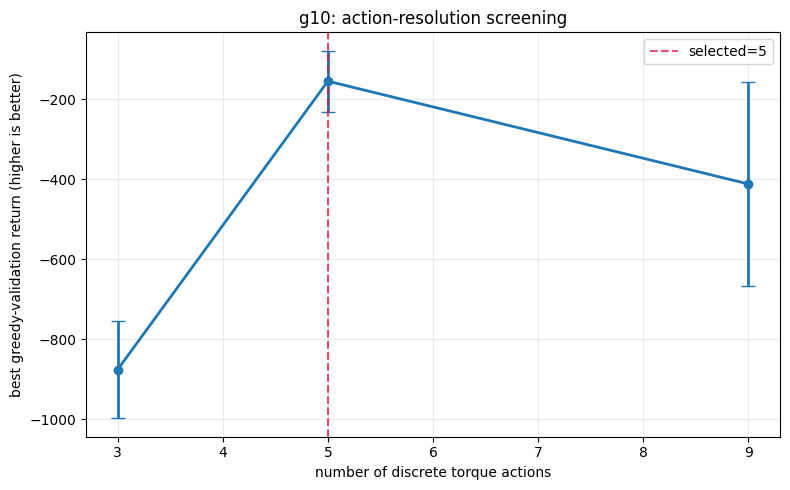

In [15]:
if SHOW_ANALYSIS_PLOTS:
    plot_action_screening_for_gravity("g10")
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — `g=10`.** Five actions were selected. Its greedy-validation result (`-154.865 +/- 76.111`) was much better than 3 actions (`-875.630`) and 9 actions (`-411.681`). This is strong evidence that three actions were too coarse, while increasing to nine added complexity without improving this controlled run.


### Action-screening plot: `g0`


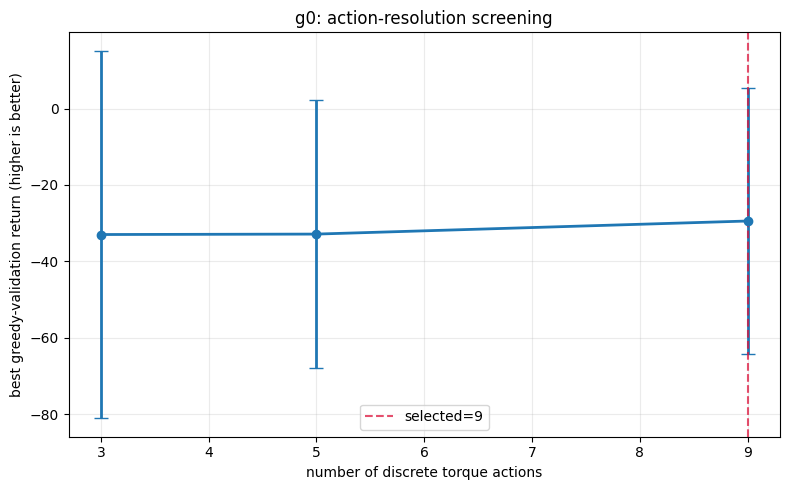

In [16]:
if SHOW_ANALYSIS_PLOTS:
    plot_action_screening_for_gravity("g0")
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — `g=0`.** Nine actions achieved the highest validation mean (`-29.427`) and the lowest SD (`34.769`) among the three candidates, although all three settings worked well. The nine-action grid was retained because it gave the best balance of return and stability.


### Action-screening plot: `g-10`


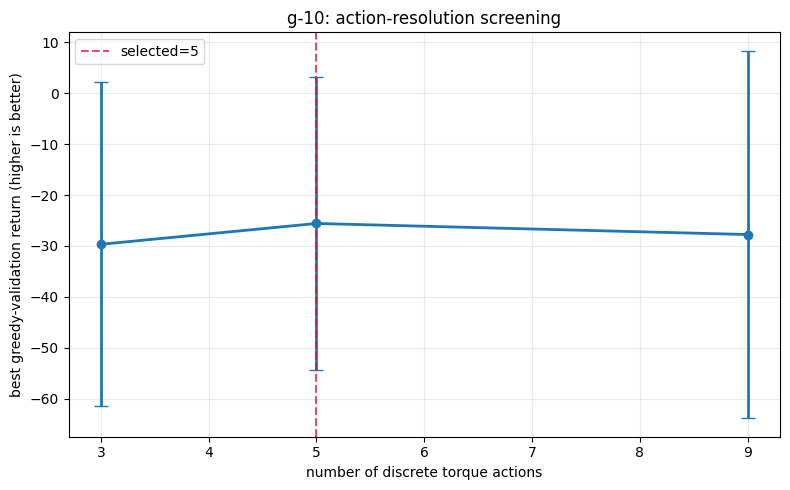

In [17]:
if SHOW_ANALYSIS_PLOTS:
    plot_action_screening_for_gravity("g-10")
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — `g=-10`.** Five actions produced the best mean (`-25.580`) and lowest SD (`28.836`). The improvement over three and nine actions was small, so the simpler five-action grid was preferred instead of using unnecessary output actions.


### Action-screening plot: `g15`


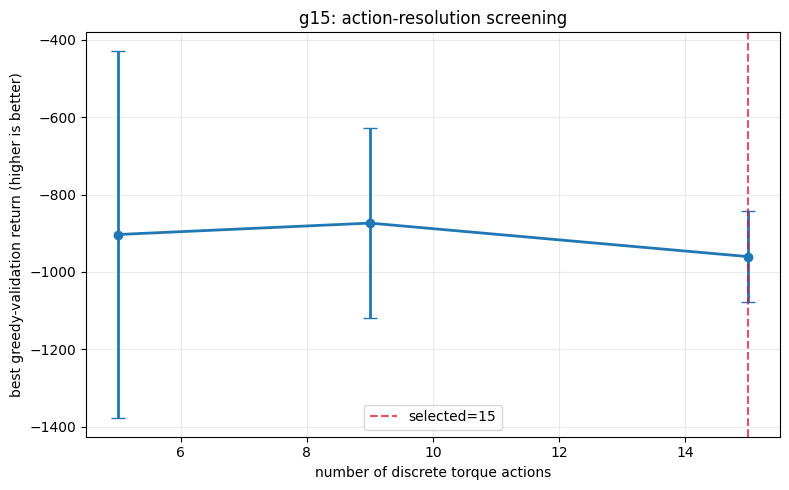

In [18]:
if SHOW_ANALYSIS_PLOTS:
    plot_action_screening_for_gravity("g15")
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — `g=15`.** Nine actions had the best short-screen mean, but 15 actions had substantially lower variability and finer torque resolution. Since all 200-episode screening means were still poor, 15 actions were treated as a stability-and-resolution choice to be tested by the longer final runs—not as the winner by short-run mean alone.


## Action-count decision table

The table below records the merged 200-episode screening evidence. Returns are greedy validation means; higher values (closer to zero) are better.

| Gravity | Candidates | Best greedy-validation evidence | Final action count | Reason |
|---|---|---|---:|---|
| `g=10` | 3, 5, 9 | 3: `-875.630 +/- 121.569`; 5: **`-154.865 +/- 76.111`**; 9: `-411.681 +/- 254.364` | 5 | Best mean and substantially lower variation than 9. |
| `g=0` | 3, 5, 9 | 3: `-32.967 +/- 48.122`; 5: `-32.851 +/- 35.071`; 9: **`-29.427 +/- 34.769`** | 9 | Highest mean and slightly lowest SD. |
| `g=-10` | 3, 5, 9 | 3: `-29.666 +/- 31.801`; 5: **`-25.580 +/- 28.836`**; 9: `-27.751 +/- 36.086` | 5 | Highest mean and lowest SD. |
| `g=15` | 5, 9, 15 | 5: `-903.440 +/- 475.351`; 9: `-873.834 +/- 246.242`; 15: `-960.646 +/- 116.947` | 15 | Nine had the best short-run mean, but all means were poor. Fifteen was far more stable and supplied the finer control resolution; its value was tested by the longer final runs. |

The frozen action counts are therefore `g10=5`, `g0=9`, `g-10=5` and `g15=15`. The `g=15` choice is a documented stability-and-resolution decision rather than a claim that it had the highest 200-episode screening mean. No configuration was selected from video appearance.


In [19]:
print("Current gravity-specific action selections")
for gravity_key, num_actions in FINAL_NUM_ACTIONS_BY_GRAVITY.items():
    print(f"  {gravity_key:5s}: {num_actions} actions -> {make_torque_grid(num_actions)}")


Current gravity-specific action selections
  g10  : 5 actions -> [-2. -1.  0.  1.  2.]
  g0   : 9 actions -> [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
  g-10 : 5 actions -> [-2. -1.  0.  1.  2.]
  g15  : 15 actions -> [-2.         -1.7142857  -1.4285715  -1.1428572  -0.85714287 -0.5714286
 -0.2857143   0.          0.2857143   0.5714286   0.85714287  1.1428572
  1.4285715   1.7142857   2.        ]


In [20]:
def target_method_run_id(mode):
    selected_actions = FINAL_NUM_ACTIONS_BY_GRAVITY["g10"]
    return f"target_g10_a{selected_actions}_{mode}_trial1"


target_method_dirs = []
for mode in ["hard_episode", "soft"]:
    run_id = target_method_run_id(mode)
    run_dir = screening_run_dir(run_id)
    target_method_dirs.append(run_dir)

    # Reuse the matching hard action-screening run if it exists.
    if mode == "hard_episode":
        reusable = screening_run_dir(
            action_screen_run_id("g10", FINAL_NUM_ACTIONS_BY_GRAVITY["g10"])
        )
        if checkpoint_complete(reusable) and not checkpoint_complete(run_dir):
            print("Hard-update evidence is already available in", reusable)
            target_method_dirs[-1] = reusable
            continue

    if RUN_TARGET_METHOD_SCREENING and RESULTS_OWNER == "youxuan":
        train_dqn(
            gravity=10.0,
            independent_run=1,
            run_id=run_id,
            run_dir=run_dir,
            num_actions=FINAL_NUM_ACTIONS_BY_GRAVITY["g10"],
            target_update_mode=mode,
            soft_tau=SOFT_UPDATE_TAU,
            max_episodes=SCREENING_EPISODES,
            min_episodes=SCREENING_EPISODES,
            enable_early_stopping=False,
            epsilon_decay_steps=SCREENING_EPSILON_DECAY_STEPS,
            kind="target_method_screening",
        )

target_method_frame = screening_summary(target_method_dirs)
display(target_method_frame.round(3))


def target_method_labels(frame):
    return frame["target_update_mode"].replace(
        {"hard_episode": "hard/episode", "soft": "soft tau=0.01"}
    )


def plot_target_validation_comparison():
    if target_method_frame.empty:
        print("Target-method validation plot skipped: results are missing.")
        return
    labels = target_method_labels(target_method_frame)
    colours = ["#4C78A8", "#F58518"][:len(target_method_frame)]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(labels, target_method_frame["best_validation_return"],
           yerr=target_method_frame["best_validation_std"], capsize=6, color=colours)
    ax.set_title("Hard versus soft: greedy-validation return and SD")
    ax.set_ylabel("return (higher is better)")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()


def plot_target_runtime_comparison():
    if target_method_frame.empty:
        print("Target-method runtime plot skipped: results are missing.")
        return
    labels = target_method_labels(target_method_frame)
    colours = ["#4C78A8", "#F58518"][:len(target_method_frame)]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(labels, target_method_frame["runtime_minutes"], color=colours)
    ax.set_title("Hard versus soft: screening runtime")
    ax.set_ylabel("minutes (lower is better)")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()


Hard-update evidence is already available in ..\results\screening\action_g10_a5_hard_episode_trial1


,run_id,gravity,num_actions,target_update_mode,soft_tau,episodes_completed,best_validation_return,best_validation_std,best_validation_episode,runtime_minutes
0,action_g10_a5_hard_episode_trial1,10.0,5,hard_episode,0.00,200,-154.865,76.111,175,2.692
1,target_g10_a5_soft_trial1,10.0,5,soft,0.01,200,-156.962,82.603,175,5.887


### Target-update comparison: validation quality


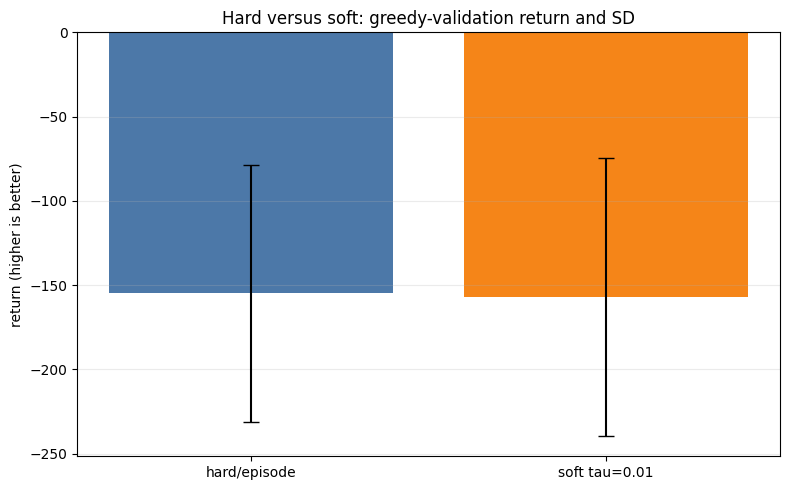

In [21]:
if SHOW_ANALYSIS_PLOTS:
    plot_target_validation_comparison()
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — validation quality.** Hard updating was slightly better: `-154.865 +/- 76.111`, compared with `-156.962 +/- 82.603` for soft updating. The difference in the mean was small, but soft updating did not improve stability in this matched experiment.


### Target-update comparison: runtime


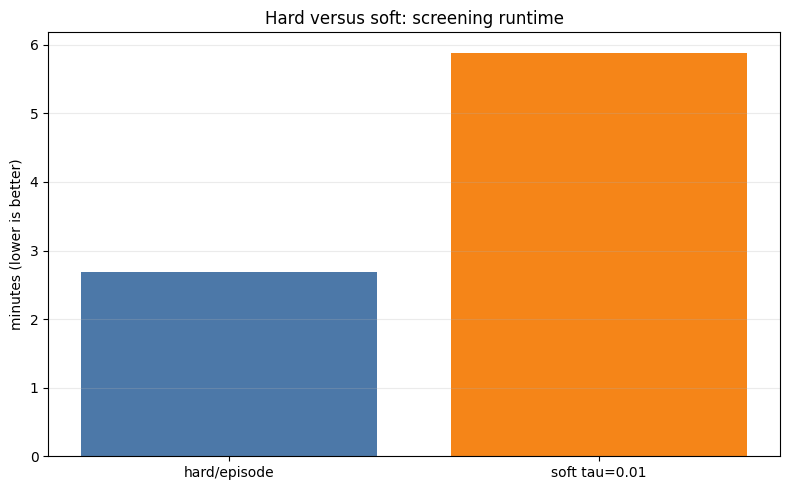

In [22]:
if SHOW_ANALYSIS_PLOTS:
    plot_target_runtime_comparison()
else:
    print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")


**Evaluation — runtime.** The soft method took `5.887` minutes versus `2.692` minutes for hard updating. Since it was slower and did not improve validation quality, the simpler hard once-per-episode update was frozen for final training.


## Target-update evidence and frozen choice

| Method | Update rule | Mean greedy validation return | Validation SD | Runtime (min) | Interpretation |
|---|---|---:|---:|---:|---|
| **Hard (selected)** | Copy Main to Target once per episode | **`-154.865`** | **`76.111`** | **`2.692`** | Slightly better return, lower variability and faster execution. |
| Soft comparison | `target = 0.99*target + 0.01*main` after each gradient update | `-156.962` | `82.603` | `5.887` | Did not improve this controlled trial and more than doubled runtime. |

**Frozen final method:** hard update once per completed episode.

Because the soft method did not improve return or stability in this matched test, it was not applied merely because it is more sophisticated. Buffer capacity remained fixed at 50,000 so that the final study stayed focused and interpretable.


In [23]:
print("FROZEN GRAVITY-SPECIFIC CONFIGURATION")
for gravity_key in GRAVITIES:
    count = FINAL_NUM_ACTIONS_BY_GRAVITY[gravity_key]
    print(f"{gravity_key:5s}: {count} actions {make_torque_grid(count)}")
print("Target update mode:", FINAL_TARGET_UPDATE_MODE)
print("Soft tau (used only if mode='soft'):", FINAL_SOFT_TAU)
print("Final budget:", MIN_FINAL_EPISODES, "to", MAX_FINAL_EPISODES, "episodes")
print("Stopping criterion after minimum episode count:")
print("  training rolling", STOPPING_WINDOW, "return >=", STOPPING_RETURN)
print("  AND current greedy validation mean >=", STOPPING_RETURN)


FROZEN GRAVITY-SPECIFIC CONFIGURATION
g10  : 5 actions [-2. -1.  0.  1.  2.]
g0   : 9 actions [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
g-10 : 5 actions [-2. -1.  0.  1.  2.]
g15  : 15 actions [-2.         -1.7142857  -1.4285715  -1.1428572  -0.85714287 -0.5714286
 -0.2857143   0.          0.2857143   0.5714286   0.85714287  1.1428572
  1.4285715   1.7142857   2.        ]
Target update mode: hard_episode
Soft tau (used only if mode='soft'): 0.01
Final budget: 500 to 2000 episodes
Stopping criterion after minimum episode count:
  training rolling 10 return >= -200.0
  AND current greedy validation mean >= -200.0


In [24]:
def run_final_gravity_specific_baselines():
    # Recreate baselines after action screening so random actions use exactly
    # the same final torque grid as the corresponding DQN.
    rows = []
    for gravity_key, gravity in GRAVITIES.items():
        torques = make_torque_grid(FINAL_NUM_ACTIONS_BY_GRAVITY[gravity_key])

        def random_selector(state, rng, grid=torques):
            index = int(rng.integers(len(grid)))
            return index, float(grid[index])

        zero_selector = lambda state, rng: (-1, 0.0)
        for baseline_name, selector in [
            ("discrete_random", random_selector),
            ("zero_torque", zero_selector),
        ]:
            episodes, _ = evaluate_action_selector(
                gravity, EVALUATION_EPISODES, selector,
                policy_name=f"final_{gravity_key}_{baseline_name}",
            )
            episodes.to_csv(
                BASELINE_DIR / f"final_{gravity_key}_{baseline_name}_episodes.csv",
                index=False,
            )
            rows.append({
                "gravity_key": gravity_key,
                "gravity": gravity,
                "num_actions": len(torques),
                "baseline": baseline_name,
                **summarise_episode_frame(episodes),
            })
    summary = pd.DataFrame(rows)
    summary.to_csv(BASELINE_DIR / "final_gravity_specific_summary.csv", index=False)
    return summary


if RUN_FINAL_BASELINES:
    display(run_final_gravity_specific_baselines().round(3))
else:
    print("Baseline generation not rerun; existing saved baseline results are loaded below.")


Baseline generation not rerun; existing saved baseline results are loaded below.


# 5. Final gravity-specific training

Each gravity receives three newly initialised agents. No model is transferred between gravities. Architecture, optimiser, replay method, epsilon schedule, hard once-per-episode Target-DQN update and evaluation protocol remain shared. The action count may differ only because Section 4 provides gravity-specific evidence; `g=15` uses 15 actions.

Every final run trains for at least **500 episodes**. Early stopping is disabled before episode 500. From episode 500 onward, a run stops only when **both** (1) the latest 10-training-episode mean return is at least `-200` and (2) a current 10-episode greedy validation mean is at least `-200`. If the training condition is met, the notebook validates the current Main DQN immediately; if validation fails the threshold, training continues. The final 30-episode evaluation is never used for stopping. Otherwise training continues up to 2,000 episodes.

| Gravity | Chun Fei | You Xuan |
|---|---|---|
| `g=10` | `run1`, `run2`, `run3` | Verify |
| `g=0` | Verify | `run1`, `run2`, `run3` |
| `g=-10` | `run1`, `run2` | `run3` |
| `g=15` | `run1` | `run2`, `run3` |

The run numbers are independent-trial labels, not random seeds or tuned variables.


In [25]:
GRAVITY_TRAIN_FLAGS = {
    "g10": TRAIN_G10,
    "g0": TRAIN_G0,
    "g-10": TRAIN_G_NEGATIVE10,
    "g15": TRAIN_G15,
}

# Six final agents are assigned to each teammate; all 12 use the same protocol.
FINAL_RUN_ASSIGNMENTS = {
    "chunfei": {"g10": [1, 2, 3], "g0": [], "g-10": [1, 2], "g15": [1]},
    "youxuan": {"g10": [], "g0": [1, 2, 3], "g-10": [3], "g15": [2, 3]},
}


def train_gravity_agents(gravity_key):
    assigned_runs = FINAL_RUN_ASSIGNMENTS[RESULTS_OWNER][gravity_key]
    num_actions = FINAL_NUM_ACTIONS_BY_GRAVITY[gravity_key]
    print(f"{RESULTS_OWNER} assigned {gravity_key} runs: {assigned_runs}")
    for run_number in assigned_runs:
        run_id = gravity_run_id(gravity_key, run_number)
        train_dqn(
            gravity=GRAVITIES[gravity_key],
            independent_run=run_number,
            run_id=run_id,
            run_dir=final_run_dir(gravity_key, run_number),
            num_actions=num_actions,
            target_update_mode=FINAL_TARGET_UPDATE_MODE,
            soft_tau=FINAL_SOFT_TAU,
            max_episodes=MAX_FINAL_EPISODES,
            min_episodes=MIN_FINAL_EPISODES,
            enable_early_stopping=True,
            epsilon_decay_steps=FINAL_EPSILON_DECAY_STEPS,
            kind="final_gravity_agent",
        )


for gravity_key, should_train in GRAVITY_TRAIN_FLAGS.items():
    if should_train:
        train_gravity_agents(gravity_key)
    else:
        print(f"{gravity_key}: training flag is False")

# Rebuild the team log from both member CSV files and from checkpoint configs.
# The config fallback is important when teammate checkpoint folders have been copied
# onto this machine but the teammate's separate results CSV was not copied.
combined_training_log = combine_member_logs()
checkpoint_rows = []
for gravity_key in GRAVITIES:
    for run_number in RUN_NUMBERS:
        config = load_config_if_available(final_run_dir(gravity_key, run_number))
        if config and config.get("kind") == "final_gravity_agent":
            checkpoint_rows.append({
                column: config.get(column, "") for column in RUN_LOG_COLUMNS
            })
if checkpoint_rows:
    combined_training_log = pd.concat(
        [combined_training_log, pd.DataFrame(checkpoint_rows)], ignore_index=True
    ).drop_duplicates(subset=["run_id"], keep="last")
    combined_training_log.to_csv(COMBINED_RESULTS_CSV, index=False)
if len(combined_training_log):
    display(combined_training_log.sort_values(["gravity", "independent_run"]).tail(20))


g10: training flag is False
g0: training flag is False
g-10: training flag is False
g15: training flag is False
Saved ..\results\results_combined.csv


,run_id,owner,kind,gravity,independent_run,num_actions,torque_values,hidden_units,learning_rate,gamma,...,stopping_return,stopping_requires_greedy_validation,stopping_reason,runtime_minutes,best_validation_return,best_validation_std,best_validation_step,best_validation_episode,checkpoint_path,status
12,g-10_run1,chunfei,final_gravity_agent,-10.0,1,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-76.8_and_greedy_validatio...,6.310006,-29.801783,21.413249,20000,100,..\results\checkpoints\g-10\run1\...,completed
13,g-10_run2,chunfei,final_gravity_agent,-10.0,2,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-47.8_and_greedy_validatio...,6.358129,-24.319882,26.354950,15000,75,..\results\checkpoints\g-10\run2\...,completed
14,g-10_run3,youxuan,final_gravity_agent,-10.0,3,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-42.1_and_greedy_validatio...,5.211900,-31.459730,29.089211,45000,225,..\results\checkpoints\g-10\run3\...,completed
9,g0_run1,youxuan,final_gravity_agent,0.0,1,9,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-62.2_and_greedy_validatio...,5.622925,-22.717901,38.559610,65000,325,..\results\checkpoints\g0\run1\be...,completed
10,g0_run2,youxuan,final_gravity_agent,0.0,2,9,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-72.5_and_greedy_validatio...,5.445066,-26.829062,33.298055,55000,275,..\results\checkpoints\g0\run2\be...,completed
11,g0_run3,youxuan,final_gravity_agent,0.0,3,9,"[-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-53.7_and_greedy_validatio...,5.434640,-33.236836,25.027443,90000,450,..\results\checkpoints\g0\run3\be...,completed
6,g10_run1,chunfei,final_gravity_agent,10.0,1,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-192.2_and_greedy_validati...,9.554239,-175.735202,110.266651,130000,650,..\results\checkpoints\g10\run1\b...,completed
7,g10_run2,chunfei,final_gravity_agent,10.0,2,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-181.4_and_greedy_validati...,6.811127,-133.991099,87.714937,101800,509,..\results\checkpoints\g10\run2\b...,completed
8,g10_run3,chunfei,final_gravity_agent,10.0,3,5,"[-2.0, -1.0, 0.0, 1.0, 2.0]","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-138.3_and_greedy_validati...,7.198093,-135.577129,109.009561,100800,504,..\results\checkpoints\g10\run3\b...,completed
15,g15_run1,chunfei,final_gravity_agent,15.0,1,15,"[-2.0, -1.7142857313156128, -1.428571462631225...","[64, 64]",0.001,0.99,...,-200.0,True,training_rolling_10_-185.8_and_greedy_validati...,7.101208,-107.418524,65.432569,101400,507,..\results\checkpoints\g15\run1\b...,completed


In [26]:
def final_checkpoint_status():
    rows = []
    for gravity_key in GRAVITIES:
        for run_number in RUN_NUMBERS:
            run_dir = final_run_dir(gravity_key, run_number)
            files = required_run_files(run_dir)
            rows.append({
                "run_id": gravity_run_id(gravity_key, run_number),
                "gravity_key": gravity_key,
                "independent_run": run_number,
                "complete": checkpoint_complete(run_dir),
                "weights_exist": files["weights"].exists(),
                "config_exists": files["config"].exists(),
                "history_exists": files["history"].exists(),
            })
    return pd.DataFrame(rows)


checkpoint_status = final_checkpoint_status()
display(checkpoint_status)
print(f"Complete final agents: {int(checkpoint_status['complete'].sum())}/12")


,run_id,gravity_key,independent_run,complete,weights_exist,config_exists,history_exists
0,g10_run1,g10,1,True,True,True,True
1,g10_run2,g10,2,True,True,True,True
2,g10_run3,g10,3,True,True,True,True
3,g0_run1,g0,1,True,True,True,True
4,g0_run2,g0,2,True,True,True,True
5,g0_run3,g0,3,True,True,True,True
6,g-10_run1,g-10,1,True,True,True,True
7,g-10_run2,g-10,2,True,True,True,True
8,g-10_run3,g-10,3,True,True,True,True
9,g15_run1,g15,1,True,True,True,True


Complete final agents: 12/12


# 6. Independent final evaluation

Final evaluation begins only after all 12 checkpoints exist. Every Main DQN is rebuilt from its own `config.json`, reloaded from its best-validation `.h5`, and evaluated greedily (`epsilon=0`) over 30 fresh randomly reset episodes.

> **Chun Fei combined copy:** the checkpoint-status output confirms that all 12 team agents were present after merging. This copy was used for the single official 30-episode evaluation and MP4 generation so the final-test protocol was not repeated or changed between teammates.

Each gravity therefore produces three agent summaries and 90 evaluation episodes. The reported gravity mean is the mean of the three independent-run means; sample SD across those three agent means measures training-run stability. This avoids pretending that 90 episodes from only one trained network are 90 independent training trials.

An upright step satisfies both `|theta| < 15 degrees` and `|angular velocity| < 1.0`. Mean absolute torque measures control effort on the common physical scale and is comparable across action grids. Maximum-torque percentage counts only actions approximately equal to `+/-2`. Time to first upright is averaged among successful episodes, while reach rate explicitly reports unsuccessful episodes.


In [27]:
AGENT_SUMMARY_PATH = EVALUATION_DIR / "evaluation_agent_summary.csv"
GRAVITY_SUMMARY_PATH = EVALUATION_DIR / "evaluation_gravity_summary.csv"


def require_all_final_checkpoints():
    # Prevent a partial team result from being mistaken for the official comparison.
    status = final_checkpoint_status()
    missing = status.loc[~status["complete"], "run_id"].tolist()
    if missing:
        raise FileNotFoundError(
            "Final evaluation requires all 12 complete checkpoints. Missing: "
            + ", ".join(missing)
        )
    return status


def evaluate_final_agent(gravity_key, run_number):
    # Reload the saved best Main-DQN checkpoint and evaluate it greedily on
    # 30 fresh episodes that were not used for training or validation.
    run_id = gravity_run_id(gravity_key, run_number)
    run_dir = final_run_dir(gravity_key, run_number)
    model, torques, config = load_model_from_run(run_dir)

    episodes, steps = evaluate_action_selector(
        GRAVITIES[gravity_key],
        EVALUATION_EPISODES,
        greedy_action_selector(model, torques),
        policy_name=run_id,
        save_steps=True,
    )
    episodes.insert(0, "run_id", run_id)
    episodes.insert(1, "gravity_key", gravity_key)
    episodes.insert(2, "independent_run", int(run_number))
    steps.insert(0, "run_id", run_id)
    steps.insert(1, "gravity_key", gravity_key)
    steps.insert(2, "independent_run", int(run_number))

    output_dir = EVALUATION_DIR / gravity_key / f"run{int(run_number)}"
    output_dir.mkdir(parents=True, exist_ok=True)
    episodes.to_csv(output_dir / "evaluation_episodes.csv", index=False)
    steps.to_csv(output_dir / "evaluation_steps.csv", index=False)

    return {
        "run_id": run_id,
        "gravity_key": gravity_key,
        "gravity": GRAVITIES[gravity_key],
        "independent_run": int(run_number),
        "best_validation_return": config["best_validation_return"],
        "best_validation_std": config["best_validation_std"],
        **summarise_episode_frame(episodes),
    }


def aggregate_agent_summaries(agent_frame):
    # Aggregate agent-level means, not 90 episodes as if they came from one
    # training run. Across-agent SD therefore reflects training variability.
    rows = []
    metric_columns = [
        "mean_return", "upright_pct", "mean_abs_angle_deg", "mean_abs_torque",
        "max_torque_pct",
        "mean_time_to_first_upright_steps", "mean_longest_upright_steps",
        "episode_reach_rate_pct",
    ]
    for gravity_key, group in agent_frame.groupby("gravity_key", sort=False):
        if len(group) != 3:
            raise ValueError(f"{gravity_key} has {len(group)} agent summaries; expected 3.")
        row = {
            "gravity_key": gravity_key,
            "gravity": float(group["gravity"].iloc[0]),
            "num_trained_agents": int(len(group)),
            "episodes_per_agent": int(group["episodes"].iloc[0]),
            "overall_mean_of_agent_returns": float(group["mean_return"].mean()),
            "std_across_agent_mean_returns": float(group["mean_return"].std(ddof=1)),
            # This records when the selected checkpoint appeared; it is supporting
            # learning-efficiency evidence, not a direct time-to-solution measure.
            "fastest_learning_best_validation_step_mean": float(np.mean([
                load_config_if_available(final_run_dir(gravity_key, run_number))["best_validation_step"]
                for run_number in RUN_NUMBERS
            ])),
        }
        for metric in metric_columns[1:]:
            row[f"mean_agent_{metric}"] = float(group[metric].mean())
        rows.append(row)
    return pd.DataFrame(rows)


if RUN_FINAL_EVALUATION:
    require_all_final_checkpoints()
    agent_rows = []
    for gravity_key in GRAVITIES:
        for run_number in RUN_NUMBERS:
            print("Evaluating", gravity_run_id(gravity_key, run_number))
            agent_rows.append(evaluate_final_agent(gravity_key, run_number))

    agent_summary = pd.DataFrame(agent_rows)
    agent_summary.to_csv(AGENT_SUMMARY_PATH, index=False)
    gravity_summary = aggregate_agent_summaries(agent_summary)
    gravity_summary.to_csv(GRAVITY_SUMMARY_PATH, index=False)
    display(agent_summary.round(3))
    display(gravity_summary.round(3))
else:
    print("Final evaluation not rerun; existing saved evaluation results are loaded below.")


Final evaluation not rerun; existing saved evaluation results are loaded below.


In [28]:
def load_final_evaluation_summaries():
    if not AGENT_SUMMARY_PATH.exists() or not GRAVITY_SUMMARY_PATH.exists():
        raise FileNotFoundError("Run final evaluation first; summary CSV files are missing.")
    return pd.read_csv(AGENT_SUMMARY_PATH), pd.read_csv(GRAVITY_SUMMARY_PATH)


def load_baseline_summary():
    path = BASELINE_DIR / "final_gravity_specific_summary.csv"
    if not path.exists():
        raise FileNotFoundError(f"Run final baselines first; missing {path}")
    return pd.read_csv(path)


baseline_summary_path = BASELINE_DIR / "final_gravity_specific_summary.csv"
if baseline_summary_path.exists():
    print("Final discrete-random and zero-torque baselines")
    display(load_baseline_summary().round(3))

if AGENT_SUMMARY_PATH.exists() and GRAVITY_SUMMARY_PATH.exists():
    agent_summary, gravity_summary = load_final_evaluation_summaries()
    # Show both levels: individual agents expose run-to-run variability, while
    # the gravity table provides the controlled four-condition comparison.
    display(agent_summary.round(3))
    display(gravity_summary.round(3))


Final discrete-random and zero-torque baselines


,gravity_key,gravity,num_actions,baseline,mean_return,std_return,upright_pct,mean_abs_angle_deg,mean_abs_torque,max_torque_pct,mean_time_to_first_upright_steps,mean_longest_upright_steps,episode_reach_rate_pct,episodes
0,g10,10.0,5,discrete_random,-1370.076,294.569,0.467,132.405,1.216,41.167,121.250,0.933,13.333,30
1,g10,10.0,5,zero_torque,-1241.427,378.149,3.800,120.370,0.000,0.000,0.250,1.633,13.333,30
2,g0,0.0,9,discrete_random,-717.553,201.994,4.467,89.129,1.108,22.300,78.571,7.900,46.667,30
3,g0,0.0,9,zero_torque,-601.555,282.954,8.250,85.107,0.000,0.000,72.524,15.400,70.000,30
4,g-10,-10.0,5,discrete_random,-714.462,468.898,2.267,68.894,1.189,38.933,45.500,2.800,13.333,30
5,g-10,-10.0,5,zero_torque,-688.378,394.124,3.333,69.076,0.000,0.000,0.000,6.667,3.333,30
6,g15,15.0,15,discrete_random,-1356.462,123.547,0.150,120.392,1.072,13.400,0.000,0.267,6.667,30
7,g15,15.0,15,zero_torque,-1390.865,167.351,0.333,124.974,0.000,0.000,0.000,0.667,10.000,30


,run_id,gravity_key,gravity,independent_run,best_validation_return,best_validation_std,mean_return,std_return,upright_pct,mean_abs_angle_deg,mean_abs_torque,max_torque_pct,mean_time_to_first_upright_steps,mean_longest_upright_steps,episode_reach_rate_pct,episodes
0,g10_run1,g10,10.0,1,-175.735,110.267,-147.984,100.586,84.333,16.602,0.982,48.067,29.867,168.567,100.000,30
1,g10_run2,g10,10.0,2,-133.991,87.715,-173.256,112.286,80.433,21.267,1.027,25.683,37.667,160.733,100.000,30
2,g10_run3,g10,10.0,3,-135.577,109.010,-106.448,61.161,85.850,11.404,0.563,24.550,28.200,171.600,100.000,30
3,g0_run1,g0,0.0,1,-22.718,38.560,-45.101,40.659,85.317,11.265,0.462,10.417,29.267,170.467,100.000,30
4,g0_run2,g0,0.0,2,-26.829,33.298,-53.124,43.993,87.167,11.368,1.356,34.500,25.667,174.333,100.000,30
5,g0_run3,g0,0.0,3,-33.237,25.027,-58.582,46.480,85.683,14.362,1.371,37.217,26.700,167.533,100.000,30
6,g-10_run1,g-10,-10.0,1,-29.802,21.413,-63.454,58.977,86.633,16.526,1.702,70.933,26.633,173.167,100.000,30
7,g-10_run2,g-10,-10.0,2,-24.320,26.355,-73.161,78.146,85.767,15.607,1.969,97.150,28.467,171.533,100.000,30
8,g-10_run3,g-10,-10.0,3,-31.460,29.089,-53.594,51.337,86.983,12.914,0.787,8.667,25.667,173.800,100.000,30
9,g15_run1,g15,15.0,1,-107.419,65.433,-411.214,578.533,70.967,39.035,1.415,49.517,29.680,141.933,83.333,30


,gravity_key,gravity,num_trained_agents,episodes_per_agent,overall_mean_of_agent_returns,std_across_agent_mean_returns,fastest_learning_best_validation_step_mean,mean_agent_upright_pct,mean_agent_mean_abs_angle_deg,mean_agent_mean_abs_torque,mean_agent_max_torque_pct,mean_agent_mean_time_to_first_upright_steps,mean_agent_mean_longest_upright_steps,mean_agent_episode_reach_rate_pct
0,g10,10.0,3,30,-142.563,33.733,110866.667,83.539,16.424,0.857,32.767,31.911,166.967,100.000
1,g0,0.0,3,30,-52.269,6.781,70000.000,86.056,12.332,1.063,27.378,27.211,170.778,100.000
2,g-10,-10.0,3,30,-63.403,9.783,26666.667,86.461,15.016,1.486,58.917,26.922,172.833,100.000
3,g15,15.0,3,30,-274.041,119.199,110666.667,78.017,27.191,1.244,39.861,33.816,155.933,94.444


## Final numerical comparison

Every value below comes from a reloaded best-validation Main-DQN checkpoint evaluated greedily on 30 fresh episodes. The final evaluation starts were not used for training, checkpoint selection or stopping.

| Gravity | Run 1 return | Run 2 return | Run 3 return | Mean across agents | Across-agent SD | Upright % | Mean abs. angle | Mean abs. torque | Reach rate |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| `g=10` | `-147.984` | `-173.256` | `-106.448` | **`-142.563`** | `33.733` | `83.539%` | `16.424 deg` | `0.857` | `100.000%` |
| `g=0` | `-45.101` | `-53.124` | `-58.582` | **`-52.269`** | **`6.781`** | `86.056%` | **`12.332 deg`** | `1.063` | `100.000%` |
| `g=-10` | `-63.454` | `-73.161` | `-53.594` | **`-63.403`** | `9.783` | **`86.461%`** | `15.016 deg` | **`1.486`** | `100.000%` |
| `g=15` | `-411.214` | `-215.253` | `-195.657` | **`-274.041`** | `119.199` | `78.017%` | `27.191 deg` | `1.244` | `94.444%` |

Higher return is better because Pendulum returns are negative; values closer to zero indicate lower angle, angular-velocity and torque penalties. The ranking is therefore `g=0`, `g=-10`, `g=10`, then `g=15`. Free-fall was both the best-performing and most reproducible condition. Reversed gravity was similarly strong and stable. Normal gravity was successful across all three trials, while supergravity was clearly the most difficult and variable.

The main supergravity outlier was `g15_run1` (`-411.214 +/- 578.533`, reach rate `83.333%`). It is retained rather than selectively retrained because it is legitimate independent-trial evidence: the other two `g=15` agents reached `-215.253` and `-195.657`, showing both that DQN can control this condition and that learning/generalisation is less reliable under the same torque limit.

`mean_abs_torque` is the directly comparable control-effort measure across the different action grids. `max_torque_pct` counts only actions approximately equal to `+/-2`, so it should not be used alone to compare a 5-action policy with the 15-action `g=15` policy. Time to first upright is averaged only over episodes that actually reached upright. The generated baseline CSV files provide the corresponding discrete-random and zero-torque reference values using each gravity's final action grid.


# 7. Visual and video evidence

Numerical evaluation has priority. The plots below answer different questions:

1. **Training diagnostics:** did learning improve, remain stable and produce plausible Q-values?
2. **Evaluation distribution:** is performance repeatable across random starts and independent training runs?
3. **Physical trajectory:** how do angle, velocity and torque evolve in representative fresh episodes?
4. **Torque distribution:** does the policy use zero torque or saturate at the ±2 limit?
5. **MP4 demonstrations:** does reloaded-checkpoint behaviour agree with the numerical evidence?

With `SHOW_ANALYSIS_PLOTS=True`, the notebook automatically displays action-screening, Target-update, personal training-diagnostic, baseline, evaluation-distribution, aggregate physical-metric, representative-trajectory and torque-distribution figures whenever their saved CSV files are available. This flag only reads existing results; it does not retrain or alter the final evaluation.


In [29]:
def load_training_diagnostic_frames(gravity_key, run_number):
    run_dir = final_run_dir(gravity_key, run_number)
    history_path = run_dir / "training_history.csv"
    if not history_path.exists():
        raise FileNotFoundError(history_path)
    history = pd.read_csv(history_path)
    return (
        history[history["record_type"] == "episode"].copy(),
        history[history["record_type"] == "update_summary"].copy(),
        history[history["record_type"] == "validation"].copy(),
    )


# These checkpoints were trained by the named teammate and provide a compact,
# personally owned diagnostic sample. All 12 agents remain in final evaluation.
PERSONAL_DIAGNOSTIC_RUNS = {
    "chunfei": [("g10", 3), ("g-10", 1), ("g15", 1)],
    "youxuan": [("g0", 2), ("g-10", 3), ("g15", 3)],
}


def plot_training_diagnostics(gravity_key, run_number):
    """Six related training diagnostics for one agent only."""
    episodes, updates, validation = load_training_diagnostic_frames(gravity_key, run_number)
    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    ax = axes.flat

    ax[0].plot(episodes["episode"], episodes["episode_return"], alpha=0.25, label="episode return")
    ax[0].plot(episodes["episode"], episodes["rolling_return_10"], linewidth=2, label="latest-10 mean")
    ax[0].axhline(STOPPING_RETURN, color="crimson", linestyle="--", label="-200 criterion")
    ax[0].axvline(MIN_FINAL_EPISODES, color="grey", linestyle=":", label="500-episode minimum")
    ax[0].set_title("Training return and stopping criterion")
    ax[0].set_xlabel("episode")
    ax[0].legend()

    ax[1].errorbar(validation["episode"], validation["validation_mean_return"],
                   yerr=validation["validation_std_return"], marker="o", capsize=3)
    ax[1].axhline(STOPPING_RETURN, color="crimson", linestyle="--")
    ax[1].set_title("Greedy validation return (10 fresh starts)")
    ax[1].set_xlabel("episode")

    ax[2].plot(updates["environment_step"], updates["loss"])
    ax[2].set_title("Huber TD loss")
    ax[2].set_xlabel("environment step")

    ax[3].plot(episodes["episode"], episodes["epsilon"])
    ax[3].set_title("Epsilon: 1 during warm-up, then decays to 0.01")
    ax[3].set_xlabel("episode")

    ax[4].plot(validation["episode"], validation["mean_max_q"], marker="o")
    ax[4].set_title("Mean maximum predicted Q-value on fixed states")
    ax[4].set_xlabel("episode")

    ax[5].plot(validation["episode"], validation["validation_upright_pct"], marker="o")
    ax[5].set_title("Greedy validation upright percentage")
    ax[5].set_xlabel("episode")

    for axis in ax:
        axis.grid(alpha=0.25)
    fig.suptitle(f"{RESULTS_OWNER}: {gravity_key} run{run_number}", fontsize=14)
    fig.tight_layout()
    plt.show()


def show_training_diagnostics(gravity_key, run_number):
    if not SHOW_ANALYSIS_PLOTS:
        print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")
        return
    try:
        plot_training_diagnostics(gravity_key, run_number)
    except (FileNotFoundError, KeyError, pd.errors.EmptyDataError) as error:
        print("Training diagnostic plot skipped:", error)


## Diagnostic-run selection rationale

Only three of Chun Fei's personally trained checkpoints are expanded into detailed six-panel diagnostics. This keeps the notebook readable while the official evaluation still includes all 12 independently trained agents.

| Displayed run | Reason for displaying it |
|---|---|
| `g10_run3` | Best `g=10` final return; provides a clear successful-control example. |
| `g-10_run1` | One of Chun Fei's assigned anti-gravity agents; supports analysis of his own training contribution. |
| `g15_run1` | His only assigned supergravity agent; its large validation-to-final-evaluation gap provides useful evidence of instability. |

> **Important:** diagnostic display selection is not model selection. All three agents for every gravity, including weaker runs such as `g15_run1`, remain in the official 30-episode evaluation and gravity-level mean/SD. The reported results are therefore not cherry-picked.


## Personal training diagnostic: `g10_run3`


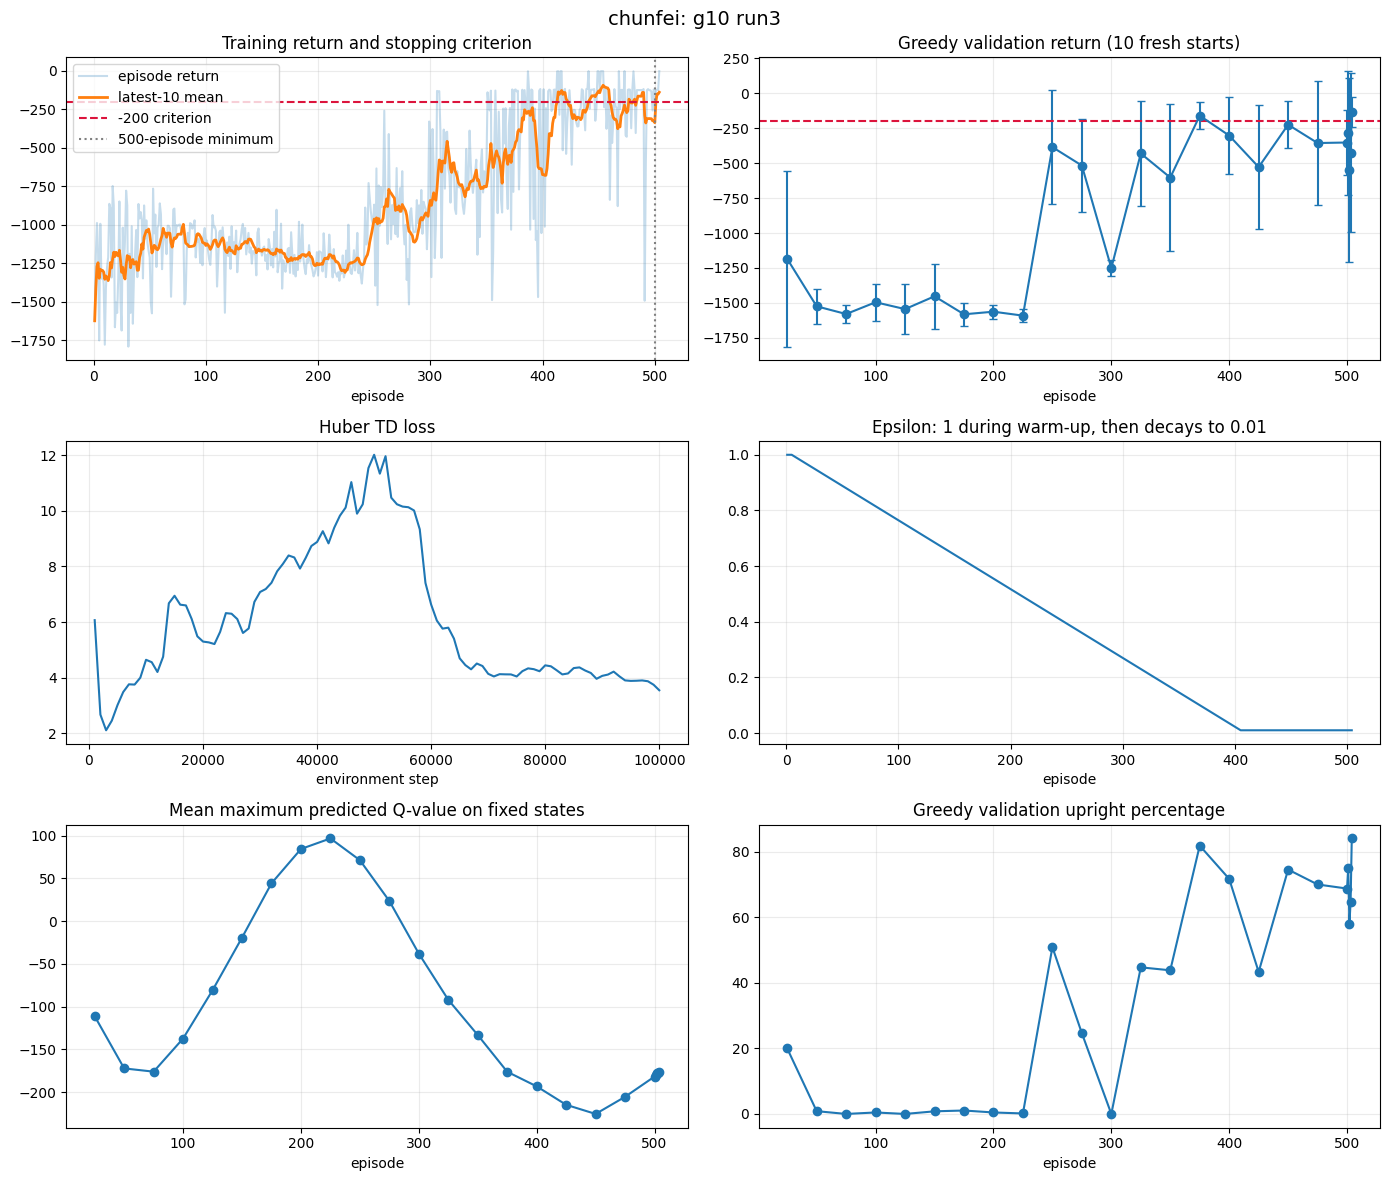

In [30]:
show_training_diagnostics("g10", 3)


**Evaluation — Chun Fei, `g10_run3`.** The six related panels should be read together: return shows learning progress, validation tests greedy behaviour, loss checks optimisation stability, epsilon confirms exploration decay, Q-values check for unstable value growth, and upright percentage connects reward to physical control. This agent achieved the strongest `g=10` final return (`-106.448`), `85.850%` upright steps, an `11.404 degree` mean absolute angle and only `0.563` mean absolute torque. It is a strong example of successful and relatively efficient control.


## Personal training diagnostic: `g-10_run1`


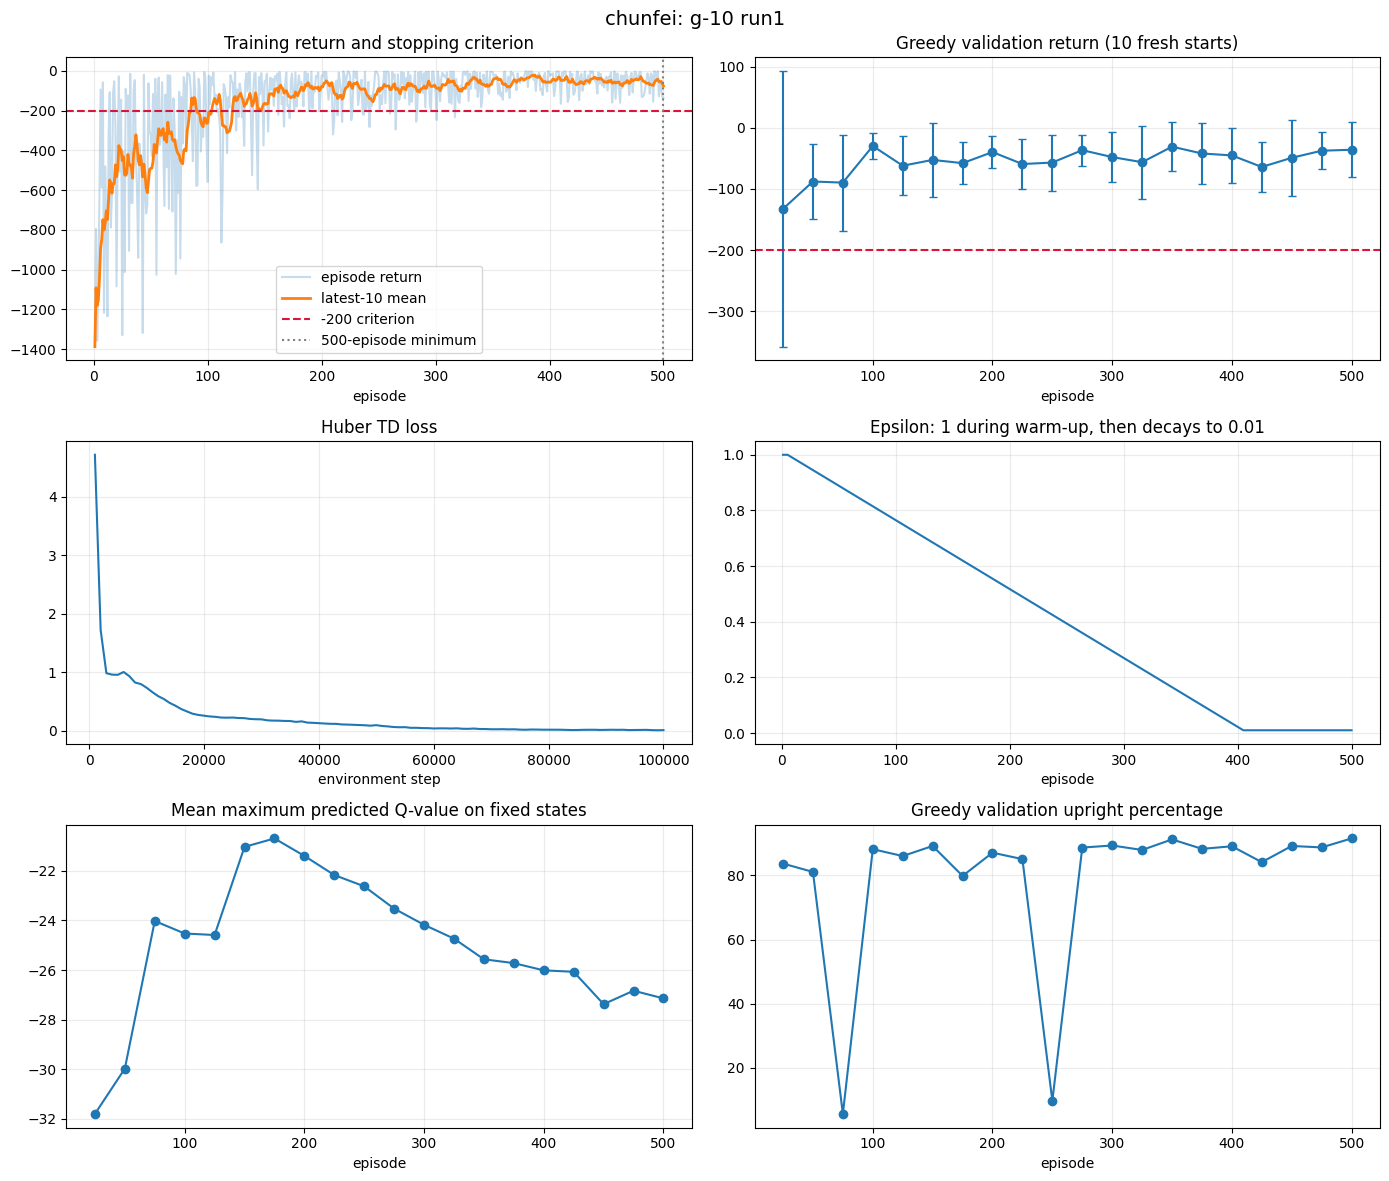

In [31]:
show_training_diagnostics("g-10", 1)


**Evaluation — Chun Fei, `g-10_run1`.** This run achieved a final mean return of `-63.454` and `86.633%` upright steps. Its mean absolute torque was relatively high (`1.702`), so the diagnostic panels help distinguish successful control from control efficiency: the pendulum stayed upright reliably, but the learned strategy used force aggressively.


## Personal training diagnostic: `g15_run1`


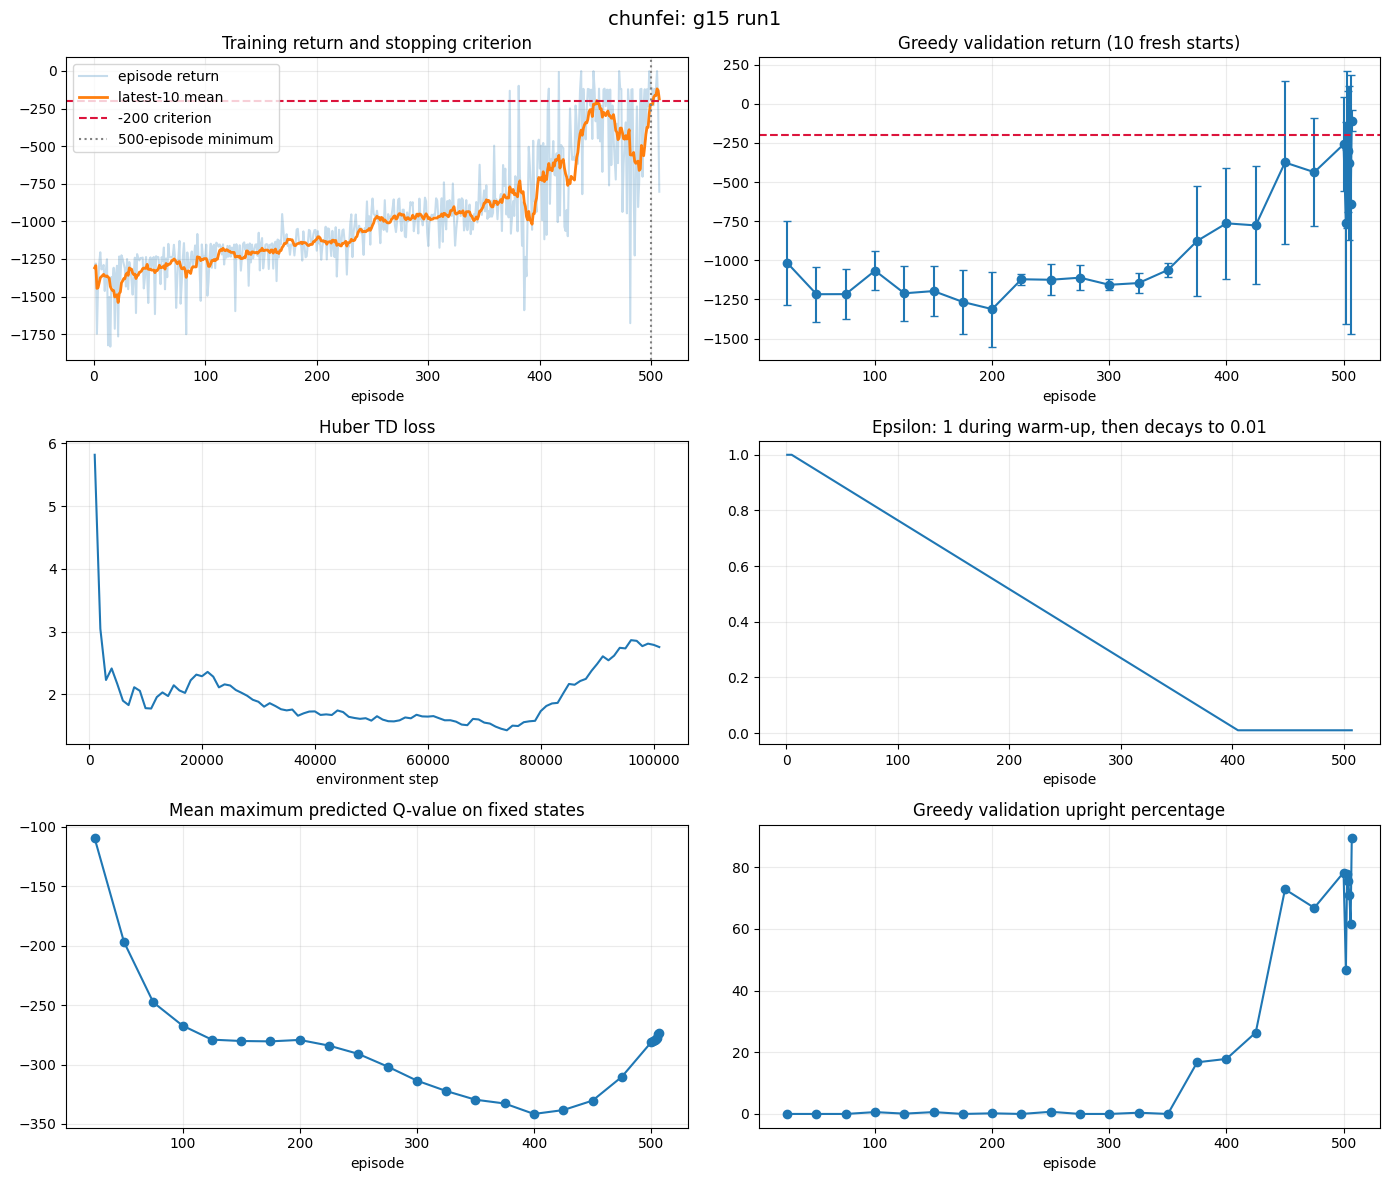

In [32]:
show_training_diagnostics("g15", 1)


**Evaluation — Chun Fei, `g15_run1`.** This is the important unstable supergravity example. Its best validation mean was strong (`-107.419`), but the 30-episode final mean was `-411.214` with very high variation (`578.533`). The gap shows why the short validation curve alone cannot prove generalisation and why this run was retained rather than selectively removed.


In [33]:
def load_all_evaluation_episodes():
    frames = []
    for gravity_key in GRAVITIES:
        for run_number in RUN_NUMBERS:
            path = EVALUATION_DIR / gravity_key / f"run{run_number}" / "evaluation_episodes.csv"
            if path.exists():
                frames.append(pd.read_csv(path))
    if not frames:
        raise FileNotFoundError("No final evaluation episode files found.")
    return pd.concat(frames, ignore_index=True)


def plot_evaluation_return_comparison():
    episodes = load_all_evaluation_episodes()
    agent_summary, _ = load_final_evaluation_summaries()
    order = list(GRAVITIES.keys())
    data = [episodes.loc[episodes["gravity_key"] == key, "episode_return"] for key in order]
    fig, ax = plt.subplots(figsize=(10, 6))
    try:
        ax.boxplot(data, tick_labels=order, showfliers=True)
    except TypeError:
        ax.boxplot(data, labels=order, showfliers=True)
    for x_position, key in enumerate(order, start=1):
        run_means = agent_summary.loc[agent_summary["gravity_key"] == key, "mean_return"]
        jitter = np.linspace(-0.08, 0.08, len(run_means))
        ax.scatter(x_position + jitter, run_means, color="crimson", s=55, zorder=3,
                   label="independent-run mean" if x_position == 1 else None)
    ax.set_ylabel("Greedy episode return (higher is better)")
    ax.set_title("Evaluation returns and three independent-agent means")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


def plot_gravity_metric_summary():
    """Four related gravity metrics in one compact evidence figure."""
    _, gravity_summary = load_final_evaluation_summaries()
    order = list(GRAVITIES.keys())
    frame = gravity_summary.set_index("gravity_key").reindex(order)
    colours = ["#4C78A8", "#72B7B2", "#54A24B", "#E45756"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].bar(order, frame["overall_mean_of_agent_returns"],
                   yerr=frame["std_across_agent_mean_returns"], capsize=5, color=colours)
    axes[0, 0].set_title("Return mean and SD across three agents")
    axes[0, 0].set_ylabel("return (higher is better)")
    axes[0, 1].bar(order, frame["mean_agent_upright_pct"], color=colours)
    axes[0, 1].set_title("Mean upright percentage")
    axes[0, 1].set_ylabel("percentage of steps")
    axes[1, 0].bar(order, frame["mean_agent_mean_abs_angle_deg"], color=colours)
    axes[1, 0].set_title("Mean absolute angle")
    axes[1, 0].set_ylabel("degrees (lower is better)")
    axes[1, 1].bar(order, frame["mean_agent_mean_abs_torque"], color=colours)
    axes[1, 1].set_title("Mean absolute torque")
    axes[1, 1].set_ylabel("absolute torque")
    for axis in axes.flat:
        axis.grid(axis="y", alpha=0.25)
    fig.suptitle("Final gravity-level evaluation metrics")
    fig.tight_layout()
    plt.show()


def plot_baseline_return_comparison():
    baseline = load_baseline_summary()
    _, gravity_summary = load_final_evaluation_summaries()
    order = list(GRAVITIES.keys())
    pivot = baseline.pivot(index="gravity_key", columns="baseline", values="mean_return").reindex(order)
    dqn = gravity_summary.set_index("gravity_key").reindex(order)["overall_mean_of_agent_returns"]
    x = np.arange(len(order), dtype=float)
    width = 0.25
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(x - width, pivot.get("discrete_random", pd.Series(index=order, dtype=float)), width,
           label="discrete random")
    ax.bar(x, pivot.get("zero_torque", pd.Series(index=order, dtype=float)), width,
           label="zero torque")
    ax.bar(x + width, dqn, width, label="DQN (three-agent mean)")
    ax.set_xticks(x, order)
    ax.set_ylabel("episode return (higher is better)")
    ax.set_title("Final DQN versus matched baseline policies")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


def show_final_plot(plot_function, required_baseline=False):
    if not SHOW_ANALYSIS_PLOTS:
        print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")
        return
    if not (AGENT_SUMMARY_PATH.exists() and GRAVITY_SUMMARY_PATH.exists()):
        print("Plot skipped: shared evaluation CSV files are missing.")
        return
    if required_baseline and not baseline_summary_path.exists():
        print("Baseline comparison skipped: final baseline summary is missing.")
        return
    try:
        plot_function()
    except (FileNotFoundError, KeyError, pd.errors.EmptyDataError) as error:
        print("Plot skipped:", error)


## Final evaluation: return distribution


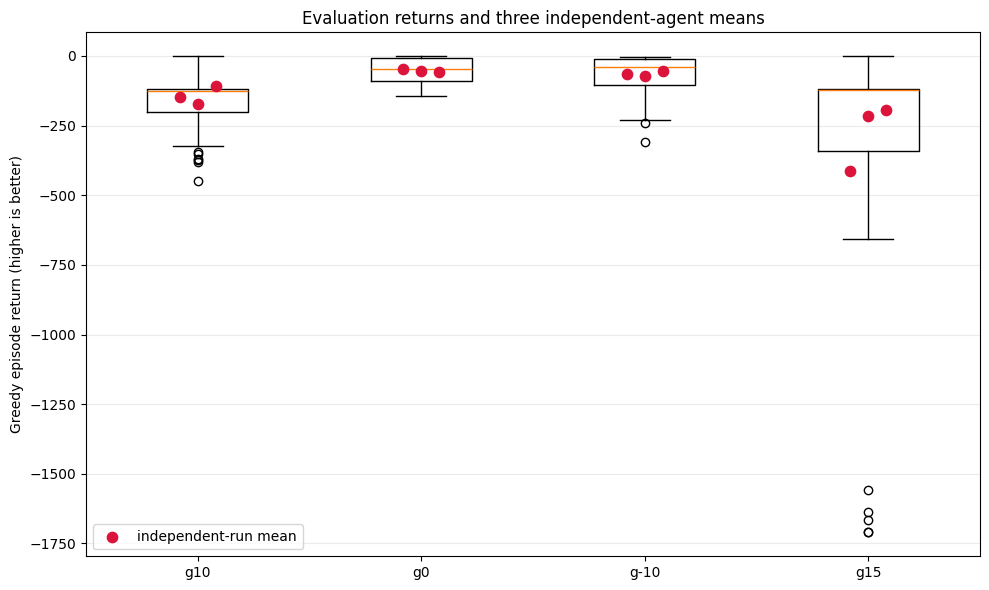

In [34]:
show_final_plot(plot_evaluation_return_comparison)


**Evaluation — return distribution.** `g=0` and `g=-10` are concentrated closest to zero, while `g=15` has the widest spread and most severe low-return episodes. The red points expose the three independently trained agent means instead of hiding training-run variation inside one pooled boxplot.


## Final evaluation: return and physical metrics


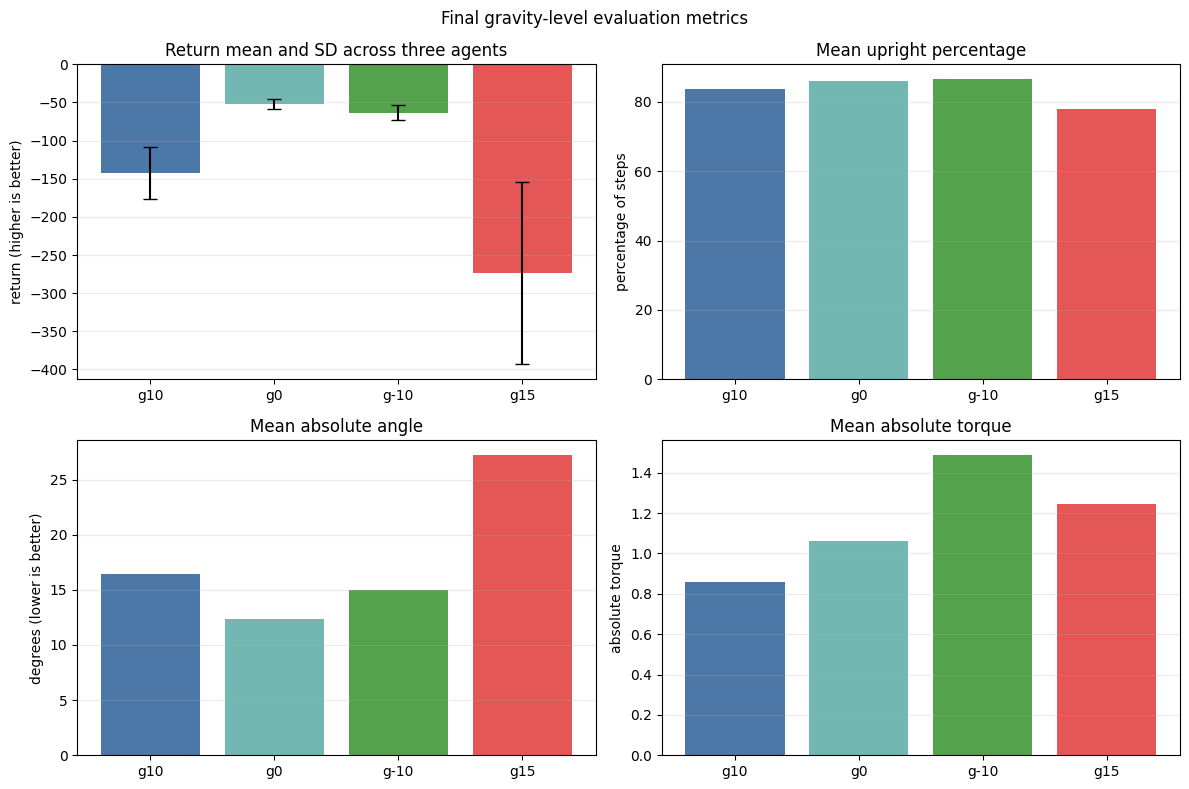

In [35]:
show_final_plot(plot_gravity_metric_summary)


**Evaluation — combined metrics.** `g=0` performed best (`-52.269`) and was most stable (across-agent SD `6.781`), followed by `g=-10` (`-63.403 +/- 9.783`). Normal gravity remained successful (`-142.563 +/- 33.733`). Supergravity was hardest (`-274.041 +/- 119.199`), with the lowest upright percentage and largest mean angle. Mean absolute torque also shows that similar returns can be achieved with different control effort.


## Final evaluation: DQN versus baseline policies


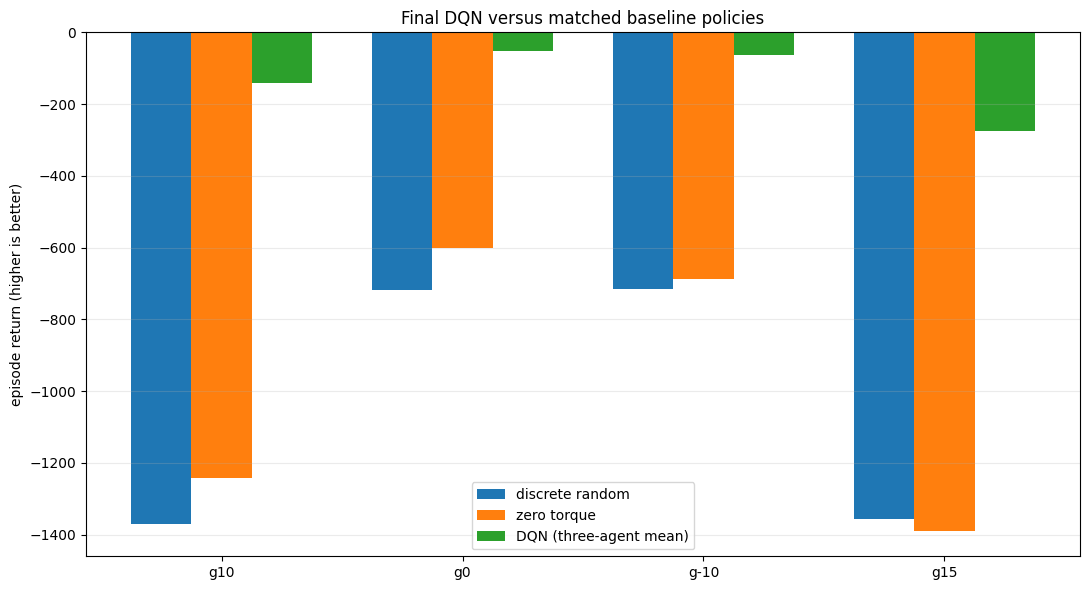

In [36]:
show_final_plot(plot_baseline_return_comparison, required_baseline=True)


**Evaluation — baselines.** The trained DQN should be compared with both discrete-random and zero-torque policies using the same gravity-specific torque grids. DQN's advantage demonstrates learned control, while the zero-torque result remains physically informative for `g=0` and `g=-10` rather than being treated as a meaningless baseline.


In [37]:
def select_demo_run(gravity_key):
    """Choose a demonstration checkpoint only from validation evidence."""
    candidates = []
    for run_number in RUN_NUMBERS:
        run_dir = final_run_dir(gravity_key, run_number)
        config = load_config_if_available(run_dir)
        if config and config.get("status") == "completed" and checkpoint_complete(run_dir):
            candidates.append(config)
    if not candidates:
        raise FileNotFoundError(f"No complete final checkpoints for {gravity_key}")
    candidates.sort(
        key=lambda item: (-float(item["best_validation_return"]), float(item["best_validation_std"]))
    )
    selected = candidates[0]
    return final_run_dir(gravity_key, selected["independent_run"]), selected


def greedy_trace(gravity_key):
    run_dir, config = select_demo_run(gravity_key)
    model, torques, _ = load_model_from_run(run_dir)
    _, steps = evaluate_action_selector(
        GRAVITIES[gravity_key], 1, greedy_action_selector(model, torques),
        policy_name=config["run_id"], save_steps=True,
    )
    return steps, config


def saved_evaluation_trace(gravity_key):
    """Load a median-return episode from the validation-selected agent."""
    agent_summary, _ = load_final_evaluation_summaries()
    candidates = agent_summary[agent_summary["gravity_key"] == gravity_key].sort_values(
        ["best_validation_return", "best_validation_std"], ascending=[False, True]
    )
    if candidates.empty:
        raise FileNotFoundError(f"No evaluation summary for {gravity_key}")
    selected = candidates.iloc[0]
    run_number = int(selected["independent_run"])
    evaluation_dir = EVALUATION_DIR / gravity_key / f"run{run_number}"
    episode_frame = pd.read_csv(evaluation_dir / "evaluation_episodes.csv")
    step_frame = pd.read_csv(evaluation_dir / "evaluation_steps.csv")
    median_return = float(episode_frame["episode_return"].median())
    chosen_index = (episode_frame["episode_return"] - median_return).abs().idxmin()
    chosen_episode = int(episode_frame.loc[chosen_index, "evaluation_episode"])
    trace = step_frame[step_frame["evaluation_episode"] == chosen_episode].copy()
    return trace, {"run_id": selected["run_id"], "episode": chosen_episode}


def plot_physical_trajectory_for_gravity(gravity_key):
    """Three tightly related state/action traces for one saved episode."""
    steps, selected = saved_evaluation_trace(gravity_key)
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    axes[0].plot(steps["step"], steps["angle_deg"])
    axes[0].axhspan(-15, 15, alpha=0.15, color="green", label="upright angle band")
    axes[0].set_ylabel("angle (degrees)")
    axes[0].legend()
    axes[1].plot(steps["step"], steps["angular_velocity"])
    axes[1].set_ylabel("angular velocity")
    axes[2].step(steps["step"], steps["torque"], where="post")
    axes[2].set_ylabel("torque")
    axes[2].set_xlabel("step")
    for axis in axes:
        axis.grid(alpha=0.2)
    fig.suptitle(
        f"{gravity_key}: saved median-return episode from {selected['run_id']} "
        f"(episode {selected['episode']})"
    )
    fig.tight_layout()
    plt.show()


def show_physical_trajectory(gravity_key):
    if not SHOW_ANALYSIS_PLOTS:
        print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")
        return
    try:
        plot_physical_trajectory_for_gravity(gravity_key)
    except (FileNotFoundError, KeyError, pd.errors.EmptyDataError) as error:
        print("Physical trajectory plot skipped:", error)


## Representative physical trajectory: `g10`


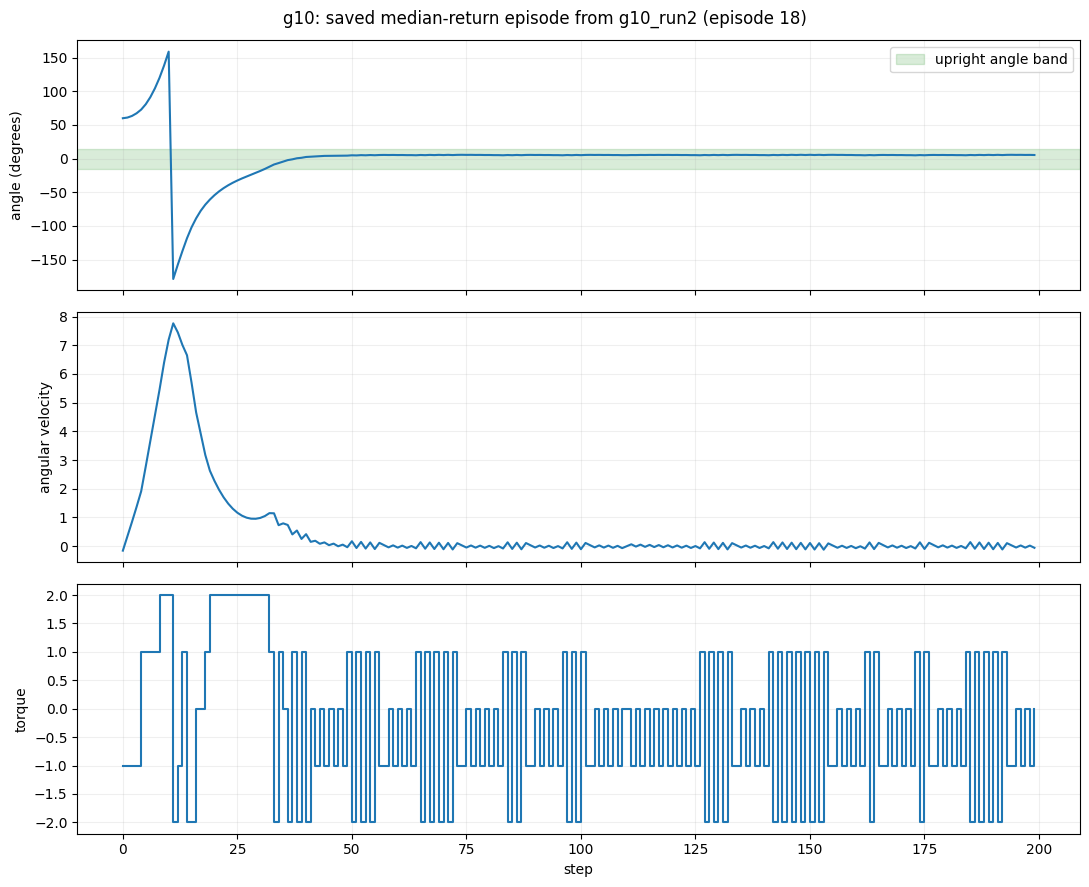

In [38]:
show_physical_trajectory("g10")


**Evaluation — `g=10` trajectory.** Angle, angular velocity and torque are shown together because they describe one control sequence. The representative episode shows an initial swing-up followed by long periods near the green upright band. This agrees with the aggregate `83.539%` upright rate and `100%` episode reach rate.


## Representative physical trajectory: `g0`


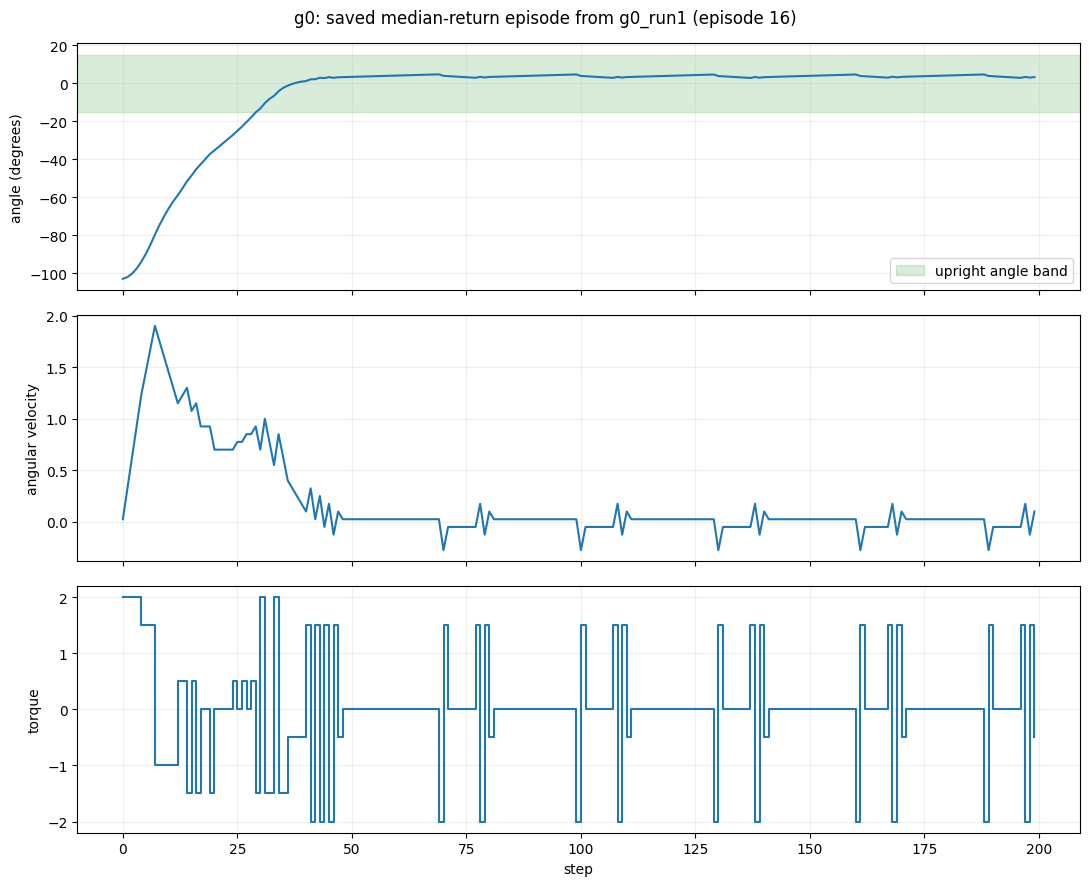

In [39]:
show_physical_trajectory("g0")


**Evaluation — `g=0` trajectory.** With no gravitational acceleration, less corrective effort is needed once the pendulum approaches upright. The long upright periods are consistent with the best gravity-level return (`-52.269`) and low mean absolute angle (`12.332 degrees`).


## Representative physical trajectory: `g-10`


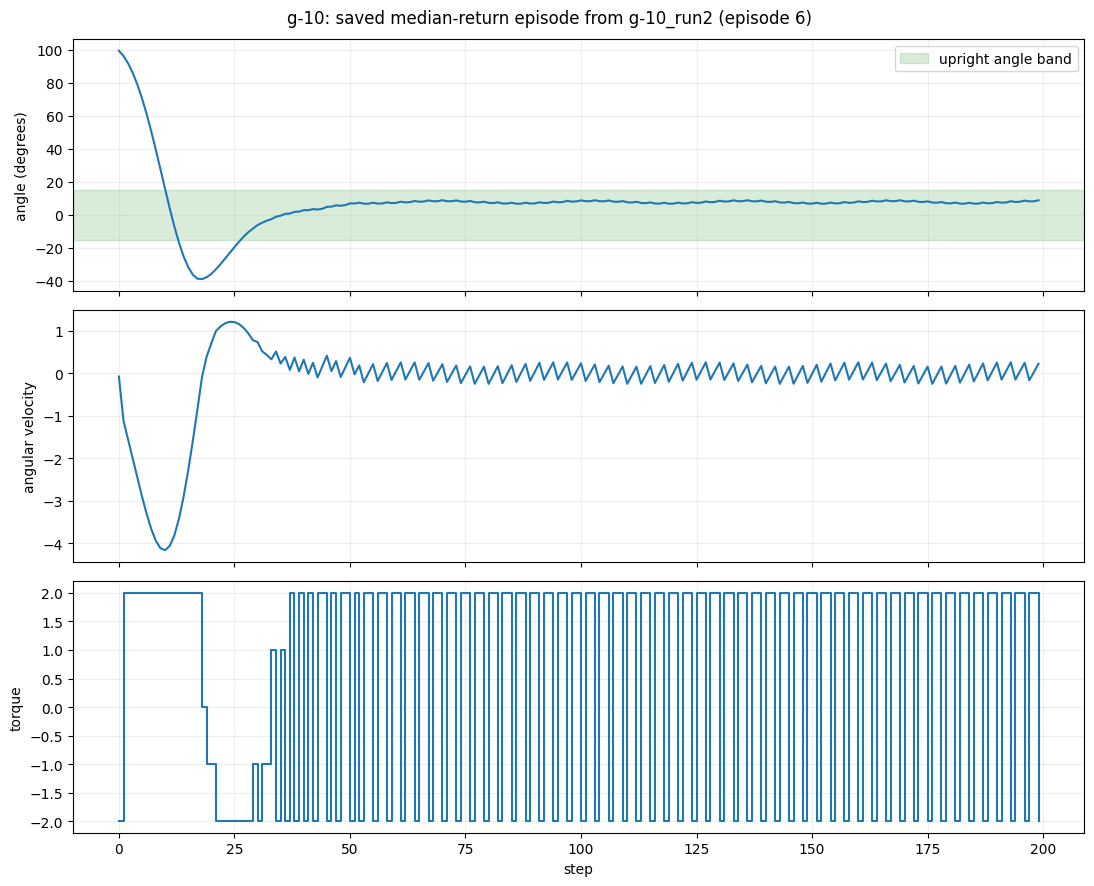

In [40]:
show_physical_trajectory("g-10")


**Evaluation — `g=-10` trajectory.** Reversed gravity makes the upright region physically favourable after the agent reaches it. The episode settles near the upright region, while the torque trace shows that some anti-gravity policies still use aggressive actions. Across agents, mean absolute torque was `1.486`.


## Representative physical trajectory: `g15`


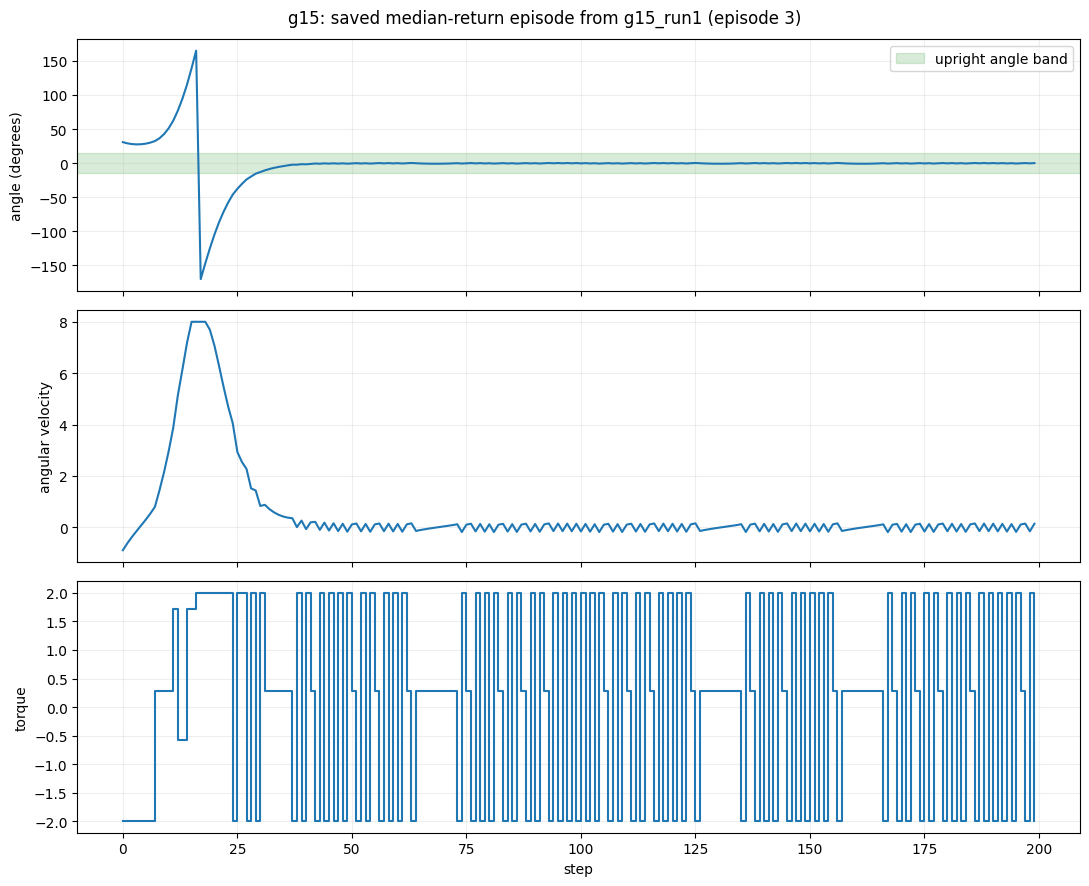

In [41]:
show_physical_trajectory("g15")


**Evaluation — `g=15` trajectory.** Supergravity produces larger deviations and more demanding recovery than the other conditions. The representative traces support the numerical result: `g=15` had the lowest upright rate (`78.017%`), largest mean angle (`27.191 degrees`) and greatest across-agent variability.


In [42]:
def load_all_evaluation_steps():
    frames = []
    for gravity_key in GRAVITIES:
        for run_number in RUN_NUMBERS:
            path = EVALUATION_DIR / gravity_key / f"run{run_number}" / "evaluation_steps.csv"
            if path.exists():
                frames.append(pd.read_csv(path))
    if not frames:
        raise FileNotFoundError("No final evaluation step files found.")
    return pd.concat(frames, ignore_index=True)


def plot_torque_distributions():
    """Four related distributions share a scale for direct comparison."""
    steps = load_all_evaluation_steps()
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for axis, gravity_key in zip(axes.flat, GRAVITIES):
        values = steps.loc[steps["gravity_key"] == gravity_key, "torque"].round(4)
        percentages = values.value_counts(normalize=True).sort_index() * 100.0
        axis.bar([str(value) for value in percentages.index], percentages.values, color="teal")
        axis.set_title(gravity_key)
        axis.set_xlabel("discrete torque")
        axis.tick_params(axis="x", rotation=45)
        axis.grid(axis="y", alpha=0.2)
    axes[0, 0].set_ylabel("percentage of evaluation steps")
    axes[1, 0].set_ylabel("percentage of evaluation steps")
    fig.suptitle("Torque-action distribution across all three trained agents")
    fig.tight_layout()
    plt.show()


def show_torque_distributions():
    if not SHOW_ANALYSIS_PLOTS:
        print("Plot disabled because SHOW_ANALYSIS_PLOTS is False.")
        return
    try:
        plot_torque_distributions()
    except (FileNotFoundError, KeyError, pd.errors.EmptyDataError) as error:
        print("Torque-distribution plot skipped:", error)


## Torque-action distributions


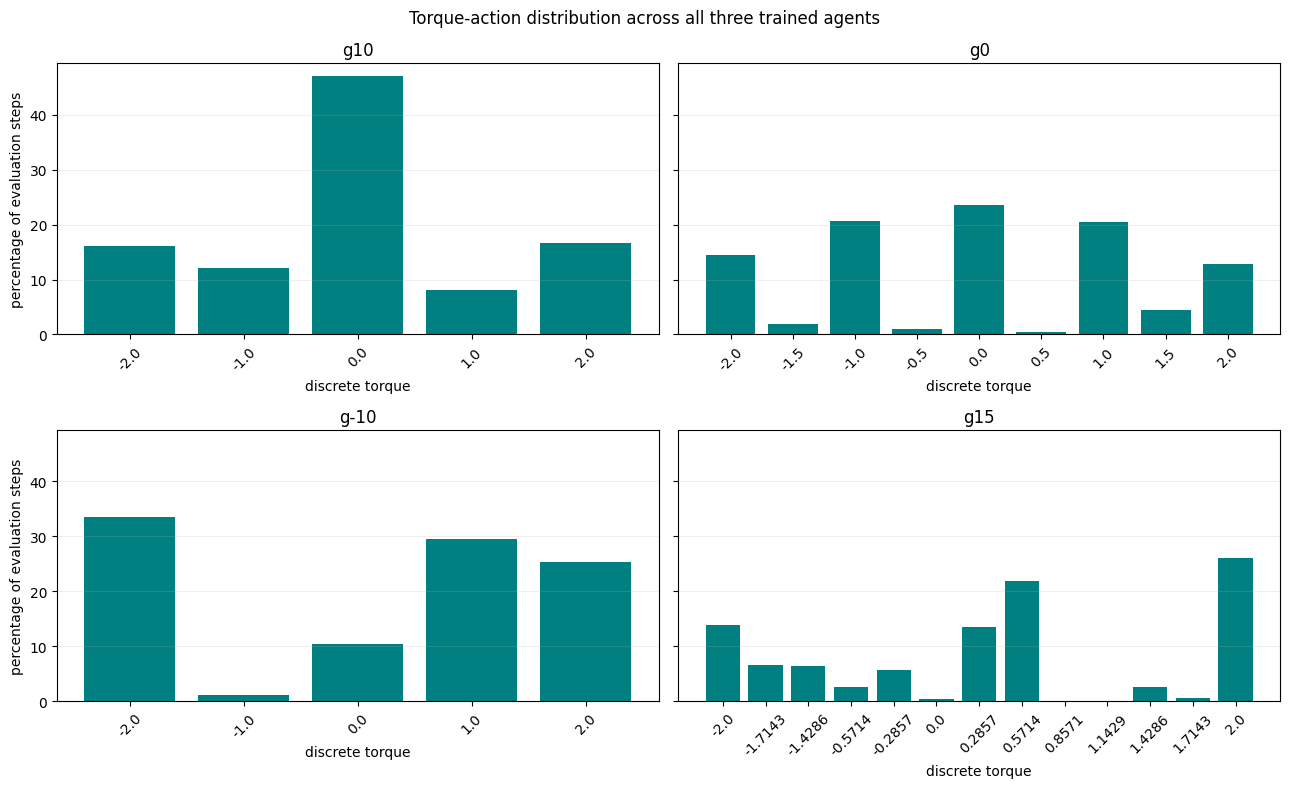

In [43]:
show_torque_distributions()


**Evaluation — torque distributions.** The panels must be interpreted together with each grid size: `g=10` and `g=-10` use five actions, `g=0` uses nine and `g=15` uses fifteen. Anti-gravity had the highest mean absolute torque (`1.486`) and maximum-torque use (`58.917%`). Supergravity used more intermediate values because its grid was finer, so maximum-torque percentage alone would not be a fair cross-gravity measure; mean absolute torque provides the common comparison.


In [44]:
def annotate_frame(frame, text_lines):
    from PIL import Image, ImageDraw
    image = Image.fromarray(np.asarray(frame, dtype=np.uint8))
    draw = ImageDraw.Draw(image)
    text = "\n".join(text_lines)
    draw.rectangle((6, 6, 360, 70), fill=(0, 0, 0))
    draw.multiline_text((12, 10), text, fill=(255, 255, 255), spacing=3)
    return np.asarray(image)


def record_gravity_video(gravity_key, video_episodes=VIDEO_EPISODES):
    # Videos are qualitative evidence generated only after numerical evaluation.
    import imageio.v2 as imageio

    run_dir, selected_config = select_demo_run(gravity_key)
    # Reload saved weights rather than using an in-memory training model.
    model, torques, _ = load_model_from_run(run_dir)
    output_path = VIDEO_DIR / f"{gravity_key}_best_dqn_3episodes.mp4"
    all_frames = []
    episode_returns = []

    for episode_number in range(1, int(video_episodes) + 1):
        env = make_pendulum_env(GRAVITIES[gravity_key])
        raw_state = env.reset()
        raw_frames = []
        episode_return = 0.0

        for _ in range(MAX_EPISODE_STEPS):
            raw_frames.append(env.render(mode="rgb_array"))
            state_tensor = tf.convert_to_tensor(normalize_state(raw_state)[None, :], dtype=tf.float32)
            action_index = int(tf.argmax(model(state_tensor, training=False)[0]).numpy())
            raw_state, reward, done, _ = env.step(
                np.array([torques[action_index]], dtype=np.float32)
            )
            episode_return += float(reward)
            if done:
                break
        env.close()
        episode_returns.append(episode_return)

        text_lines = [
            f"gravity={GRAVITIES[gravity_key]:g}  episode={episode_number}/{video_episodes}",
            f"checkpoint={selected_config['run_id']}  return={episode_return:.1f}",
        ]
        all_frames.extend([annotate_frame(frame, text_lines) for frame in raw_frames])

    imageio.mimsave(str(output_path), all_frames, format="FFMPEG", fps=30, codec="libx264")
    print("Saved", output_path, "episode returns:", np.round(episode_returns, 1).tolist())
    return output_path, episode_returns


if RECORD_VIDEOS:
    require_all_final_checkpoints()
    _video_display = start_virtual_display_if_available()
    for gravity_key in GRAVITIES:
        record_gravity_video(gravity_key)
else:
    print("Video generation not rerun; previously generated MP4 files remain in the videos folder.")


Video generation not rerun; previously generated MP4 files remain in the videos folder.


## MP4 demonstrations from saved Main-DQN checkpoints

The four demonstrations below are **qualitative evidence** supporting the numerical evaluation. Each MP4 contains three episodes and was generated only after final evaluation by reloading a saved Main-DQN checkpoint. The videos were not used to select or improve a model, so the 30-episode final evaluation remains independent.

A relative folder path is used, so the notebook works on any machine with the repository's `results/` folder in place. Running these display cells does not retrain the DQN or regenerate any video.


In [1]:
from pathlib import Path
from IPython.display import Video, display

# A relative path keeps the notebook portable across machines.
VIDEO_DIR = Path("../results") / "videos"


def show_saved_gravity_video(gravity_key, width=650):
    # Display one existing three-episode MP4 without generating new results.
    video_path = VIDEO_DIR / f"{gravity_key}_best_dqn_3episodes.mp4"

    if not video_path.exists():
        print(f"Video not found: {video_path.resolve()}")
        available = sorted(VIDEO_DIR.rglob("*.mp4")) if VIDEO_DIR.exists() else []
        if available:
            print("Available MP4 files:")
            for path in available:
                print(" -", path)
        return

    print("Displaying:", video_path)
    display(Video(filename=str(video_path), embed=True, width=width))


### Demonstration: default gravity (`g=10`)

This is the normal-gravity control task. The video provides a visual check of swing-up and upright stabilisation, while the official conclusion remains based on all three agents and 90 final evaluation episodes.


In [ ]:
show_saved_gravity_video("g10")


Displaying: ..\results\videos\g10_best_dqn_3episodes.mp4


**Interpretation.** Across the three independently trained agents, `g=10` achieved a mean return of `-142.563`, an upright percentage of `83.539%` and a `100%` episode reach rate. The MP4 is therefore representative qualitative evidence, not a replacement for the aggregated measurements.


### Demonstration: free-fall (`g=0`)

With gravity removed, the video shows the controller acting without a downward gravitational pull. This condition should be interpreted together with its zero-torque baseline because the underlying physics is easier than normal gravity.


In [3]:
show_saved_gravity_video("g0")


Displaying: ..\results\videos\g0_best_dqn_3episodes.mp4


**Interpretation.** `g=0` produced the strongest and most reproducible aggregate result: mean return `-52.269`, across-agent SD `6.781`, upright percentage `86.056%` and a `100%` reach rate. The visual behaviour is consistent with the reduced control difficulty, but the numerical comparison remains primary.


### Demonstration: anti-gravity (`g=-10`)

Reversed gravity makes the upright region physically favourable. The video helps show how the learned controller manages motion around that region rather than assuming that anti-gravity requires no control.


In [4]:
show_saved_gravity_video("g-10")


Displaying: ..\results\videos\g-10_best_dqn_3episodes.mp4


**Interpretation.** `g=-10` achieved mean return `-63.403`, across-agent SD `9.783`, upright percentage `86.461%` and a `100%` reach rate. Its mean absolute torque was nevertheless the highest (`1.486`), demonstrating why return, physical state and control effort must be considered together.


### Demonstration: supergravity (`g=15`)

Supergravity is the most demanding condition because the torque remains restricted to `[-2, 2]`. This video is particularly useful for observing slower recovery, larger oscillation or occasional loss of the upright region that may be hidden by a single mean return.


In [5]:
show_saved_gravity_video("g15")


Displaying: ..\results\videos\g15_best_dqn_3episodes.mp4


**Interpretation.** `g=15` was successful but least stable: mean return `-274.041`, across-agent SD `119.199`, upright percentage `78.017%` and episode reach rate `94.444%`. The MP4 supports the conclusion that supergravity is the principal stability limitation under the fixed torque bound; it does not justify adjusting that environment constraint.


# 8. Evidence-based discussion

### 8.1 Did the agents learn?

The learning curves, greedy-validation checkpoints and final evaluation answer different questions. Training return measures behaviour while epsilon-greedy exploration is still active. Ten fresh greedy validation episodes are used to decide whether the current policy is reliable enough to stop and to save the best checkpoint. Thirty further greedy episodes per agent are reserved for the final evaluation. The generated final-baseline table places the DQN results beside discrete-random and zero-torque policies using the same gravity-specific action grids; this comparison should be interpreted together with the physics because zero torque can itself be informative at `g=0` and `g=-10`. Independently of a single return curve, the trained policies reached upright in 100% of final episodes for `g=10`, `g=0` and `g=-10`, and 94.444% for `g=15`. This combination of baseline policies, independent checkpoints, fresh starts and physical metrics is stronger evidence than reward alone.

The team defined a satisfactory run as one that completed at least 500 episodes and then simultaneously achieved a latest-10 training mean and a current 10-episode greedy-validation mean of at least `-200`. The threshold is a team-defined experimental criterion rather than an official Gym solved score. It prevents stopping after one lucky training episode. The best checkpoint can occur before or at the stopping point because it is selected from all scheduled greedy validations completed up to that point, using higher mean return and then lower SD as a tie-break. Final evaluation remains untouched by both decisions.

### 8.2 What was systematically optimised?

The continuous torque interval `[-2,2]` was discretised so DQN could output one Q-value per action. Every odd grid contains zero, allowing the controller to coast rather than always applying force. Action count was screened separately by gravity while architecture, optimiser and update rule were held fixed. The selected grids were 5 actions for `g=10`, 9 for `g=0`, 5 for `g=-10` and 15 for `g=15`. The supergravity selection is explicitly a stability-and-resolution decision: 9 actions had the highest short-screen mean, whereas 15 actions had far lower SD and supplied finer control for the longer final investigation.

Epsilon is the probability of a random action. It remains `1.0` during the 1,000-step replay warm-up, when no gradient learning occurs, and then decays linearly to `0.01`. This gives broad early experience without continuing unnecessary random actions after a policy has formed. A second controlled experiment compared hard Target-DQN updates with soft updates at `g=10`, using the selected 5-action grid. Hard updating produced `-154.865 +/- 76.111` in 2.692 minutes; soft updating produced `-156.962 +/- 82.603` in 5.887 minutes. Because added complexity did not improve return or stability, the hard once-per-episode method was frozen for all final agents.

The team's primary definition of 'best' is the highest mean greedy validation return, with lower validation SD used when means differ by at most one return point. Final quality is then reported as the mean and SD across three independently trained agents on 30 fresh episodes each. Learning efficiency is described by the episode/step at which the best validation checkpoint appeared, but this is supporting evidence rather than a substitute for final generalisation.

### 8.3 How did gravity change the task?

At `g=0`, there is no gravitational acceleration, so once the agent moves the pendulum near upright it is comparatively easy to keep it there; this condition achieved the best mean return (`-52.269`) and lowest across-agent SD (`6.781`). With `g=-10`, gravity is reversed and the upright region becomes physically favourable. Its return (`-63.403`) and SD (`9.783`) were also strong, although its mean absolute torque (`1.486`) was the largest, showing that high performance does not imply identical control effort.

Normal gravity remained controllable: all three agents reached upright in all 30 evaluation episodes and averaged `-142.563`. Supergravity was hardest. It had the poorest mean return (`-274.041`), largest across-agent SD (`119.199`), largest mean angle (`27.191 deg`) and lowest reach rate (`94.444%`). The three-episode video evidence tells the same story: two `g=15` demonstrations were strong but one return was about `-586`, whereas the other gravities were more consistent. This is not hidden as a failure; it demonstrates why repeated independent runs and a held-out final evaluation were necessary.

### 8.4 Chun Fei's individual analytical focus

**Normal gravity (`g=10`).** I trained all three normal-gravity agents. Their final returns were `-147.984`, `-173.256` and `-106.448`, with every agent reaching upright in all 30 evaluation episodes. `g10_run3` was strongest: it combined the best return with the lowest mean absolute angle (`11.404 deg`) and lowest mean absolute torque (`0.563`). This suggests a more efficient policy rather than improvement caused simply by using maximum torque more often. The three-agent mean of `-142.563 +/- 33.733` shows that the selected 5-action configuration was reasonably repeatable.

**Assigned anti-gravity runs.** My `g-10_run1` and `run2` achieved `-63.454` and `-73.161`, with upright percentages of `86.633%` and `85.767%`. Both used aggressive control: mean absolute torque was `1.702` and `1.969`, and run2 selected approximately maximum torque on `97.150%` of steps. You Xuan's run3 achieved a similar or better return with much lower torque, showing that independent DQN agents can discover different successful strategies in the reversed-gravity environment.

**Assigned supergravity run and integration.** My `g15_run1` illustrates the difference between validation and final generalisation. Its best 10-episode validation mean was `-107.419`, but its 30-episode final mean fell to `-411.214 +/- 578.533`; it reached upright in `83.333%` of episodes. I retained this result rather than selectively retraining it because it is valid evidence of instability under difficult starts. I also merged all 12 checkpoint folders, handled cross-version weight compatibility, ran the combined 30-episode evaluation and generated the final MP4 demonstrations from reloaded Main-DQN weights.

### 8.5 Limitations

DQN approximates a naturally continuous problem with a finite torque grid, and the grids differ by gravity, so gravity and action resolution cannot be separated perfectly in the final cross-gravity comparison. Three unseeded independent runs expose training variability but are not exactly reproducible. Ten validation episodes can still give an optimistic estimate, illustrated by `g15_run1`: its best validation mean was `-107.419`, but its 30-episode final mean was `-411.214`. The final test therefore must remain a held-out set, and the outlier must not be selectively removed. Finally, [van Hasselt, Guez and Silver (2016)](https://arxiv.org/abs/1509.06461) shows that Vanilla DQN can overestimate Q-values; DDQN is therefore a reasonable future extension, but it was
left out here so the standard DQN could be explained thoroughly first. It is tested in the follow-up notebook `dqn_vs_double_dqn.ipynb`. A second
natural extension is a **continuous-action baseline** such as [DDPG (Lillicrap et al., 2016)](https://arxiv.org/abs/1509.02971), which
would remove the quantisation floor described in Section 3 entirely and separate "how much of the
residual error is the discrete grid" from "how much is the learning algorithm" — a question this
study can raise but cannot answer within a DQN-only design.


## Conclusion

> We implemented an efficient Vanilla DQN with experience replay, separate Main and Target networks, state normalisation and odd discrete torque grids containing zero. Under the final protocol, epsilon remained at `1.0` during replay warm-up, decayed only after gradient training began and reached `0.01`. We screened action resolution by gravity and used 15 actions for supergravity. A controlled hard-versus-soft comparison retained the simpler hard once-per-episode Target-DQN update because it was slightly better, more stable and faster in the matched trial. Each independently initialised agent trained for at least 500 episodes and could stop only when both the latest-10 training mean and current 10-episode greedy-validation mean reached `-200`. Reloaded Main-DQN checkpoints were then evaluated greedily over 30 fresh episodes. The agents performed best and most consistently at `g=0` (`-52.269 +/- 6.781` across agent means) and `g=-10` (`-63.403 +/- 9.783`), remained successful at `g=10` (`-142.563 +/- 33.733`), and were least reliable at `g=15` (`-274.041 +/- 119.199`). Thus the investigation demonstrates successful DQN control under all four gravities while honestly showing that supergravity is the main generalisation and stability limitation under the fixed torque bound.


## Source-to-implementation mapping and references

Only sources that directly informed an implemented method, the environment definition, or a stated limitation are included. The table identifies the **specific part used** and separates literature-backed principles from our own experimental choices.

| Clickable source and title | Specific part referenced | How it was applied in this notebook |
|---|---|---|
| [Mnih et al. (2015), *Human-level control through deep reinforcement learning*](https://www.nature.com/articles/nature14236) | DQN algorithm description: replay memory, a separate Target DQN and periodic target updates; Figure 2's monitoring of average predicted action value. | Implemented a replay buffer, separate Main and Target DQNs, best-checkpoint validation and mean maximum-Q diagnostics. We adapted the mechanisms to a 3-value Pendulum state and did **not** copy the Atari convolutional architecture. |
| [Sutton & Barto (2018), *Reinforcement Learning: An Introduction*, 2nd ed.](https://incompleteideas.net/book/the-book-2nd.html) | Section 2.4 on epsilon-greedy exploration; Section 6.5 on one-step Q-learning. | Defined epsilon as the probability of a random action and used the one-step target `r + gamma max Q(s',a)`. The warm-up length and decay endpoints are our tuned engineering choices. |
| [Brockman et al. (2016), *OpenAI Gym*](https://arxiv.org/abs/1606.01540) | The benchmark toolkit's common environment interface and comparable task setup. | Used Gym 0.17.3's `reset()`/`step()` interaction pattern and the same environment interface for all four gravity conditions. |
| [OpenAI Gym 0.17.3, `PendulumEnv` source](https://github.com/openai/gym/blob/0.17.3/gym/envs/classic_control/pendulum.py#L22-L85) | `__init__`, `step()` and `_get_obs()`: configurable gravity, torque clipping, dynamics, cost/reward and `[cos(theta), sin(theta), theta_dot]` observation. | Created separate environments for `g=10`, `0`, `-10` and `15`; retained the official `[-2,2]` torque bound; discretised only that official interval; normalised the three supplied observation values. |
| [Lillicrap et al. (2016), *Continuous control with deep reinforcement learning*](https://arxiv.org/abs/1509.02971) | Introduction on why DQN requires discrete actions and the limitations of naive discretisation; Algorithm 1's soft Target-network update. | Used the action-space discussion to justify torque discretisation and action-count screening. Adapted only the soft interpolation rule for the hard-versus-soft comparison; DDPG itself was not implemented. |
| [van Hasselt, Guez & Silver (2016), *Deep Reinforcement Learning with Double Q-learning*](https://arxiv.org/abs/1509.06461) | Abstract and Double-DQN method explaining overestimation when action selection and evaluation are coupled. | Used only to identify a limitation of Vanilla DQN and justify DDQN as future work. The reported agents remain Vanilla DQN. |
| Deep learning course lab notebook: CartPole DQN (internal, not publicly available) | Lab structure for a Main/Target DQN, replay memory and an epsilon-greedy Gym 0.17.3 training loop. | Adapted the CartPole structure to Pendulum by normalising the state, replacing CartPole actions with a finite torque grid, adding gravity-specific environments and adding controlled screening/evaluation. |

### Full reference details

1. Mnih, V., Kavukcuoglu, K., Silver, D., et al. (2015). [*Human-level control through deep reinforcement learning*](https://doi.org/10.1038/nature14236). **Nature, 518**, 529–533.
2. Sutton, R. S., & Barto, A. G. (2018). [*Reinforcement Learning: An Introduction* (2nd ed.)](https://incompleteideas.net/book/the-book-2nd.html). MIT Press.
3. Brockman, G., Cheung, V., Pettersson, L., et al. (2016). [*OpenAI Gym*](https://arxiv.org/abs/1606.01540). arXiv:1606.01540.
4. OpenAI. (2020). [*Gym 0.17.3 `PendulumEnv` implementation*](https://github.com/openai/gym/blob/0.17.3/gym/envs/classic_control/pendulum.py#L22-L85). GitHub source code.
5. Lillicrap, T. P., Hunt, J. J., Pritzel, A., et al. (2016). [*Continuous control with deep reinforcement learning*](https://arxiv.org/abs/1509.02971). ICLR 2016.
6. van Hasselt, H., Guez, A., & Silver, D. (2016). [*Deep Reinforcement Learning with Double Q-learning*](https://arxiv.org/abs/1509.06461). AAAI-16.
7. Deep learning course lab notebook: *CartPole DQN* (2026). Internal teaching material, not publicly available.


## Execution order used

The project was executed one expensive stage at a time. The sequence below records the workflow used to produce the saved results. In this saved notebook, all expensive flags remain `False`, while saved-result visualisations remain enabled.

1. Both teammates: `RUN_INFRASTRUCTURE_TESTS`
2. Both teammates: `RUN_VIDEO_SMOKE_TEST`
3. Both teammates: `RUN_RUNTIME_BENCHMARK`
4. Run `RUN_PRELIMINARY_BASELINES` for an initial check
5. Both teammates: `RUN_ACTION_SCREENING` on their assigned gravities
6. Keep the merged screening evidence and freeze the selected action counts as `g10=5`, `g0=9`, `g-10=5`, `g15=15`
7. You Xuan: `RUN_TARGET_METHOD_SCREENING` to retain hard-versus-soft evidence
8. Confirm the screening decision: `FINAL_TARGET_UPDATE_MODE="hard_episode"` (soft `tau=0.01` remains comparison evidence only)
9. Run `RUN_FINAL_BASELINES` once using the final action grids
10. Each teammate trains only their assigned final gravity runs
11. Merge `results/checkpoints/` and both teammates' result CSV files
12. Confirm `12/12` complete checkpoints
13. Run `RUN_FINAL_EVALUATION` once on the combined copy
14. Produce diagnostic and comparison figures
15. Run `RECORD_VIDEOS` only after numerical evaluation
16. Set `SHOW_ANALYSIS_PLOTS=True` and run the notebook with the saved `screening/`, `checkpoints/`, `baselines/` and `evaluation/` folders beside it to rebuild all figures without retraining
